## Imports and plotting configuration

The project configuration selects the FLASH data paths. `FLASH_ENV=remote` is retained from the working analysis for use on the ASAP3 server.

In [62]:
import os
import sys
import re
import json
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

%matplotlib inline

os.environ.setdefault("FLASH_ENV", "remote")


def find_repo_root(start=None):
    '''Find the repository containing analysis/scripts.'''
    start = Path.cwd().resolve() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "analysis" / "scripts").exists():
            return path
    raise RuntimeError("Could not find repository root containing analysis/scripts")


repo_root = find_repo_root()
scripts_dir = repo_root / "analysis" / "scripts"
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))

import config
from compute_aggregates import load_aggregates

AggregatesData = load_aggregates.__globals__["AggregatesData"]

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.grid": False,
})

In [135]:
# --- Delay-scan loading configuration ---

AGG_DIR = Path(config.COMBINED_DIR)

SCAN_STEM = "glycine_delay_scan_150C"
# SCAN_STEM = "glycine_delay_scan_7June_147C"
AGG_SUFFIX = "_aggregates_tr_etof1.h5"

#Change between datasets
EXPECTED_ENERGIES = np.round(np.arange(271.5, 275.0 + 0.25, 0.5), 1)
# EXPECTED_ENERGIES = np.round(np.arange(274.0, 276.0 + 0.25, 0.5), 1)

LOW_GMD_RANGE = (0.6, 1.3)
HIGH_GMD_RANGE = (1.3, 2.0)

CHUNK_TRAINS = 1000
MIN_SHOTS_PER_GROUP = 500
MIN_SUM_GMD_PER_GROUP = 100.0

E_TOF_KEY = "tofs_e"
DATA_FAMILY = "delay_collapsed"

# Same native eTOF grid used by the earlier config-1 aggregate notebooks:
# 5000 bins spanning [0, 5000) in 100 ps units.
DEFAULT_TOF_EDGES = np.arange(0, 5000 + 1, 1.0)

files = []
missing = []

for energy in EXPECTED_ENERGIES:
    path = AGG_DIR / f"{SCAN_STEM}_{energy:.1f}eV{AGG_SUFFIX}"
    if path.exists():
        files.append((path, float(energy)))
    else:
        missing.append(path.name)

if missing:
    raise FileNotFoundError(
        "Missing expected aggregate files:\n  " + "\n  ".join(missing)
    )

print(f"Found {len(files)} files:")
for path, energy in files:
    print(f"  {energy:6.1f} eV  {path.name}")

Found 8 files:
   271.5 eV  glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1.h5
   272.0 eV  glycine_delay_scan_150C_272.0eV_aggregates_tr_etof1.h5
   272.5 eV  glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5
   273.0 eV  glycine_delay_scan_150C_273.0eV_aggregates_tr_etof1.h5
   273.5 eV  glycine_delay_scan_150C_273.5eV_aggregates_tr_etof1.h5
   274.0 eV  glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5
   274.5 eV  glycine_delay_scan_150C_274.5eV_aggregates_tr_etof1.h5
   275.0 eV  glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5


In [136]:
# --- Minimal aggregate metadata reader, strict axes ---

from types import SimpleNamespace


def inspect_h5_shallow(path):
    """Inspect H5 layout without reading large arrays."""
    path = Path(path)
    print("\nFILE:", path)
    print("exists:", path.exists())
    if path.exists():
        print("size bytes:", path.stat().st_size)

    with h5py.File(path, "r") as handle:
        print("\nattrs:")
        for key, value in handle.attrs.items():
            print(f"  {key}: {value}")

        print("\ntop-level items:")
        for key in handle.keys():
            obj = handle[key]
            if isinstance(obj, h5py.Dataset):
                print(f"  {key}: shape={obj.shape}, dtype={obj.dtype}")
            else:
                print(f"  {key}: group")


def load_delay_scan_metadata(path):
    """
    Read only small metadata/axes from the aggregate.

    Strict by design: delay-collapsed analysis still needs the aggregate
    tof_edges and z_edges to define the valid native bins.
    """
    path = Path(path)

    with h5py.File(path, "r") as handle:
        metadata = {}
        for key in handle.attrs:
            value = handle.attrs[key]
            if isinstance(value, bytes):
                value = value.decode()
            elif isinstance(value, np.ndarray):
                value = value.tolist()
            metadata[key] = value

        def read_required_axis(key):
            if key not in handle:
                raise KeyError(
                    f"{path.name} has no /{key} dataset. "
                    "Run inspect_h5_shallow(path) to check the file layout."
                )
            return handle[key][:]

        return SimpleNamespace(
            path=path,
            metadata=metadata,
            tof_edges=read_required_axis("tof_edges"),
            z_edges=read_required_axis("z_edges"),
            gmd_edges=read_required_axis("gmd_edges"),
        )


def source_h5_from_aggregate_file(agg_path, agg=None):
    agg_path = Path(agg_path)
    agg = load_delay_scan_metadata(agg_path) if agg is None else agg

    input_h5 = agg.metadata.get("input_h5", "")
    if isinstance(input_h5, bytes):
        input_h5 = input_h5.decode()

    candidates = []

    if input_h5:
        candidates.append(Path(input_h5))

    stem = agg_path.name.replace(AGG_SUFFIX, "")
    candidates.append(agg_path.parent / f"{stem}.h5")

    for candidate in candidates:
        if candidate.exists():
            return candidate

    raise FileNotFoundError(
        f"Source H5 not found for {agg_path.name}\n"
        + "\n".join(f"  tried: {candidate}" for candidate in candidates)
    )

### Collapse all delays

In [137]:
# --- Collapse all valid delay bins into low/high GMD spectra ---

def keep_mask_like_compute_aggregates_from_h5(handle, trim_start=0, trim_end=0):
    """Reproduce the train-level selection used during aggregate generation."""
    if "between_tdc_files" not in handle:
        return np.ones(handle["gmd"].shape[0], dtype=bool)

    between_tdc_files = handle["between_tdc_files"][:].astype(bool)
    good_positions = np.where(~between_tdc_files)[0]

    if trim_end > 0:
        good_positions = good_positions[trim_start:-trim_end]
    else:
        good_positions = good_positions[trim_start:]

    keep = np.zeros(between_tdc_files.shape[0], dtype=bool)
    keep[good_positions] = True
    return keep


def shot_group_spectrum_from_h5(
    source_h5,
    gmd_range,
    tof_edges,
    z_edges,
    *,
    trim_start=0,
    trim_end=0,
    chunk_trains=1000,
):
    """Return sum(counts)/sum(GMD), collapsing all valid delay bins."""
    source_h5 = Path(source_h5)
    gmd_lo, gmd_hi = gmd_range

    tof_edges = np.asarray(tof_edges, dtype=float)
    z_edges = np.asarray(z_edges, dtype=float)

    if z_edges.ndim != 1 or z_edges.size < 2:
        raise ValueError(f"Invalid z_edges shape: {z_edges.shape}")

    total_counts = np.zeros(len(tof_edges) - 1, dtype=np.float64)
    total_gmd = 0.0
    total_shots = 0
    total_hits = 0
    total_rejected_delay = 0

    with h5py.File(source_h5, "r") as handle:
        for key in ["gmd", E_TOF_KEY, "z"]:
            if key not in handle:
                raise KeyError(f"{source_h5.name} has no dataset /{key}")

        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=trim_start,
            trim_end=trim_end,
        )

        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep]
            tofs = handle[E_TOF_KEY][start:stop][row_keep]
            z = handle["z"][start:stop][row_keep]

            if z.shape != gmd.shape:
                raise ValueError(
                    f"{source_h5.name}: z shape {z.shape} "
                    f"does not match gmd shape {gmd.shape}"
                )

            if tofs.shape[:-1] != gmd.shape:
                raise ValueError(
                    f"{source_h5.name}: {E_TOF_KEY} shot shape {tofs.shape[:-1]} "
                    f"does not match gmd shape {gmd.shape}"
                )

            delay_bin = np.searchsorted(z_edges, z, side="right") - 1
            valid_delay = (
                np.isfinite(z)
                & (delay_bin >= 0)
                & (delay_bin < len(z_edges) - 1)
            )

            gmd_flat = gmd.reshape(-1)
            tofs_flat = tofs.reshape(-1, tofs.shape[-1])
            valid_delay_flat = valid_delay.reshape(-1)

            selected = (
                valid_delay_flat
                & np.isfinite(gmd_flat)
                & (gmd_flat >= gmd_lo)
                & (gmd_flat < gmd_hi)
            )

            total_rejected_delay += int(np.count_nonzero(~valid_delay_flat))

            if not selected.any():
                continue

            hits = tofs_flat[selected].reshape(-1)
            hits = hits[np.isfinite(hits) & (hits > 0)]

            histogram, _ = np.histogram(hits, bins=tof_edges)

            total_counts += histogram.astype(np.float64)
            total_gmd += float(np.nansum(gmd_flat[selected]))
            total_shots += int(np.count_nonzero(selected))
            total_hits += int(hits.size)

    with np.errstate(invalid="ignore", divide="ignore"):
        spectrum = total_counts / total_gmd
    spectrum[~np.isfinite(spectrum)] = np.nan

    return {
        "spectrum": spectrum,
        "counts": total_counts,
        "sum_gmd": total_gmd,
        "shots": total_shots,
        "hits": total_hits,
        "gmd_range": gmd_range,
        "rejected_delay_shots": total_rejected_delay,
    }


def low_high_from_delay_scan_source(agg_path):
    agg = load_delay_scan_metadata(agg_path)
    source_h5 = source_h5_from_aggregate_file(agg_path, agg=agg)

    trim_start = int(agg.metadata.get("trim_start", 0) or 0)
    trim_end = int(agg.metadata.get("trim_end", 0) or 0)

    tof_edges = np.asarray(agg.tof_edges, dtype=float)
    z_edges = np.asarray(agg.z_edges, dtype=float)

    low = shot_group_spectrum_from_h5(
        source_h5,
        LOW_GMD_RANGE,
        tof_edges,
        z_edges,
        trim_start=trim_start,
        trim_end=trim_end,
        chunk_trains=CHUNK_TRAINS,
    )

    high = shot_group_spectrum_from_h5(
        source_h5,
        HIGH_GMD_RANGE,
        tof_edges,
        z_edges,
        trim_start=trim_start,
        trim_end=trim_end,
        chunk_trains=CHUNK_TRAINS,
    )

    difference = high["spectrum"] - low["spectrum"]
    with np.errstate(invalid="ignore", divide="ignore"):
        fractional = 2.0 * difference / (high["spectrum"] + low["spectrum"])
    fractional[~np.isfinite(fractional)] = np.nan

    return {
        "source_h5": source_h5,
        "tof_edges": tof_edges,
        "z_edges": z_edges,
        "low": low,
        "high": high,
        "diff": difference,
        "frac": fractional,
        "trim_start": trim_start,
        "trim_end": trim_end,
    }

In [138]:
# --- Load all requested energies into full_rows ---

full_rows = []
tof_edges_ref = None

for agg_path, energy in files:
    print(f"Loading {energy:.1f} eV: {agg_path.name}")

    result = low_high_from_delay_scan_source(agg_path)

    if tof_edges_ref is None:
        tof_edges_ref = result["tof_edges"]
    elif not np.array_equal(tof_edges_ref, result["tof_edges"]):
        raise ValueError(f"TOF edge mismatch in {agg_path.name}")

    low = result["low"]
    high = result["high"]

    usable = (
        low["shots"] >= MIN_SHOTS_PER_GROUP
        and high["shots"] >= MIN_SHOTS_PER_GROUP
        and low["sum_gmd"] >= MIN_SUM_GMD_PER_GROUP
        and high["sum_gmd"] >= MIN_SUM_GMD_PER_GROUP
    )

    full_rows.append({
        "energy": float(energy),
        "path": agg_path,
        "source_h5": result["source_h5"],
        "family": DATA_FAMILY,
        "low": low,
        "high": high,
        "diff": result["diff"],
        "frac": result["frac"],
        "usable": usable,
        "z_edges": result["z_edges"],
        "trim_start": result["trim_start"],
        "trim_end": result["trim_end"],
    })

if not full_rows:
    raise RuntimeError("No rows loaded")

for row in full_rows:
    expected = f"{SCAN_STEM}_{row['energy']:.1f}eV.h5"
    if row["source_h5"].name != expected:
        raise ValueError(
            f"{row['energy']:.1f} eV: expected {expected}, "
            f"got {row['source_h5'].name}"
        )

print("All energies use the expected shot-resolved source H5.")

incident_energies = np.array([row["energy"] for row in full_rows], dtype=float)

print("\nLoaded delay-collapsed rows:")
print("  rows:", len(full_rows))
print("  energy range:", incident_energies.min(), "to", incident_energies.max(), "eV")
print("  TOF bins:", len(tof_edges_ref) - 1)

print("\nPer-energy summary:")
for row in full_rows:
    low = row["low"]
    high = row["high"]
    print(
        f"  {row['energy']:6.1f} eV  usable={row['usable']}  "
        f"low shots={low['shots']:8d}, sumGMD={low['sum_gmd']:10.1f}, "
        f"bad delay={low['rejected_delay_shots']:8d}  "
        f"high shots={high['shots']:8d}, sumGMD={high['sum_gmd']:10.1f}, "
        f"bad delay={high['rejected_delay_shots']:8d}"
    )

Loading 271.5 eV: glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1.h5
Loading 272.0 eV: glycine_delay_scan_150C_272.0eV_aggregates_tr_etof1.h5
Loading 272.5 eV: glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5
Loading 273.0 eV: glycine_delay_scan_150C_273.0eV_aggregates_tr_etof1.h5
Loading 273.5 eV: glycine_delay_scan_150C_273.5eV_aggregates_tr_etof1.h5
Loading 274.0 eV: glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5
Loading 274.5 eV: glycine_delay_scan_150C_274.5eV_aggregates_tr_etof1.h5
Loading 275.0 eV: glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5
All energies use the expected shot-resolved source H5.

Loaded delay-collapsed rows:
  rows: 8
  energy range: 271.5 to 275.0 eV
  TOF bins: 5000

Per-energy summary:
   271.5 eV  usable=True  low shots=  213518, sumGMD=  201970.1, bad delay=   19190  high shots=  214108, sumGMD=  350224.8, bad delay=   19190
   272.0 eV  usable=True  low shots=  388207, sumGMD=  366127.7, bad delay=       0  high shots=  382330,

In [139]:
# --- Delay-validity diagnostic per loaded source ---

print("Delay validity summary:")
for row in full_rows:
    total_invalid = row["low"]["rejected_delay_shots"]
    selected_low = row["low"]["shots"]
    selected_high = row["high"]["shots"]

    with h5py.File(row["source_h5"], "r") as handle:
        n_shots_total = np.prod(handle["gmd"].shape)

    print(
        f"{row['energy']:6.1f} eV  "
        f"invalid delay shots={total_invalid:8d}  "
        f"fraction of all source shots={total_invalid / n_shots_total:.4%}  "
        f"low selected={selected_low:8d}  "
        f"high selected={selected_high:8d}"
    )

Delay validity summary:
 271.5 eV  invalid delay shots=   19190  fraction of all source shots=0.9530%  low selected=  213518  high selected=  214108
 272.0 eV  invalid delay shots=       0  fraction of all source shots=0.0000%  low selected=  388207  high selected=  382330
 272.5 eV  invalid delay shots=     303  fraction of all source shots=0.0088%  low selected=  387066  high selected=  384219
 273.0 eV  invalid delay shots=     303  fraction of all source shots=0.0083%  low selected=  171314  high selected=  231089
 273.5 eV  invalid delay shots=     101  fraction of all source shots=0.0030%  low selected=   98474  high selected=  162082
 274.0 eV  invalid delay shots=     101  fraction of all source shots=0.0030%  low selected=  100254  high selected=  165046
 274.5 eV  invalid delay shots=     101  fraction of all source shots=0.0029%  low selected=  116069  high selected=  181541
 275.0 eV  invalid delay shots=       0  fraction of all source shots=0.0000%  low selected=  139257 

## Analysis

### Calibration

In [142]:
# --- eTOF calibration and map helpers ---

TOF_RANGE = (800, 1100)
KE_XLIM = (180, 280)
#Change between datasets
CONTROL_ENERGY_EV = 274.0
FRAC_DENOM_MIN = 1e-4

CALIB_PATH = (
    Path(config.COMBINED_DIR).parent
    / "Calibrations"
    / "etof_energy_calibration_t0_scan.json"
)

with open(CALIB_PATH, "r", encoding="utf-8") as handle:
    calib = json.load(handle)

best_t0 = calib["t0_tof_units"]
best_slope = calib["slope_eV_tof_unit2"]
best_E0 = calib["E0_eV"]


def tof_to_ke(tof):
    tof = np.asarray(tof, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ke = best_slope / (tof - best_t0) ** 2 + best_E0
    return np.where(tof > best_t0, ke, np.nan)


def half_step_edges(values):
    values = np.asarray(values, dtype=float)
    if values.size == 1:
        return np.array([values[0] - 0.5, values[0] + 0.5])

    midpoints = 0.5 * (values[:-1] + values[1:])
    return np.concatenate([
        [2 * values[0] - midpoints[0]],
        midpoints,
        [2 * values[-1] - midpoints[-1]],
    ])


def tof_spectrum_to_ke_density(tof_edges, spectrum, tof_range):
    """Convert counts/uJ/TOF-bin to counts/uJ/eV on native unequal KE grid."""
    tof_edges = np.asarray(tof_edges, dtype=float)
    spectrum = np.asarray(spectrum, dtype=float)
    tof_centres = 0.5 * (tof_edges[:-1] + tof_edges[1:])

    mask = np.ones_like(tof_centres, dtype=bool)
    if tof_range[0] is not None:
        mask &= tof_centres >= tof_range[0]
    if tof_range[1] is not None:
        mask &= tof_centres <= tof_range[1]

    indices = np.where(mask)[0]
    if indices.size == 0:
        raise ValueError(f"No TOF bins inside range {tof_range}")

    lo = int(indices[0])
    hi = int(indices[-1]) + 1

    ke_edges = tof_to_ke(tof_edges[lo : hi + 1])
    ke_centres = tof_to_ke(tof_centres[lo:hi])
    density = spectrum[lo:hi] / np.abs(np.diff(ke_edges))

    good = np.isfinite(ke_centres) & np.isfinite(density)
    order = np.argsort(ke_centres[good])

    return ke_centres[good][order], density[good][order]


def tof_map_to_ke_density(tof_edges, data, tof_range):
    """Convert final axis of a TOF map to native unequal-bin KE density."""
    tof_edges = np.asarray(tof_edges, dtype=float)
    tof_centres = 0.5 * (tof_edges[:-1] + tof_edges[1:])

    mask = np.ones_like(tof_centres, dtype=bool)
    if tof_range[0] is not None:
        mask &= tof_centres >= tof_range[0]
    if tof_range[1] is not None:
        mask &= tof_centres <= tof_range[1]

    indices = np.where(mask)[0]
    if indices.size == 0:
        raise ValueError(f"No TOF bins inside range {tof_range}")

    lo = int(indices[0])
    hi = int(indices[-1]) + 1

    ke_edges = tof_to_ke(tof_edges[lo : hi + 1])
    data_ke = np.asarray(data, dtype=float)[..., lo:hi]
    data_ke = data_ke / np.abs(np.diff(ke_edges))

    if ke_edges[0] > ke_edges[-1]:
        ke_edges = ke_edges[::-1]
        data_ke = data_ke[..., ::-1]

    return ke_edges, data_ke

print("Calibration:", CALIB_PATH)
print("t0, slope, E0:", best_t0, best_slope, best_E0)

Calibration: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/Calibrations/etof_energy_calibration_t0_scan.json
t0, slope, E0: 70.31711711711705 172656057.91151598 -32.01574693372097


### Visual check

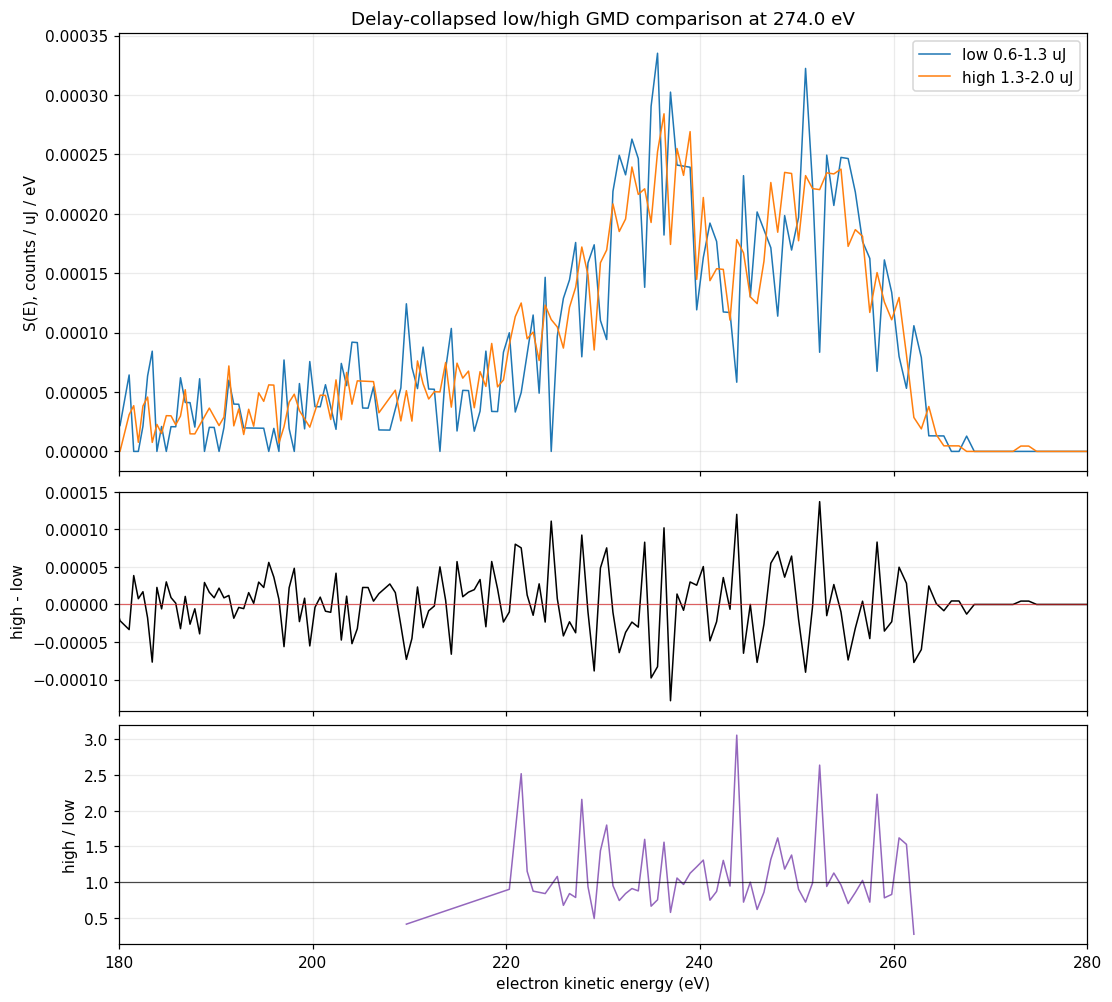

Control row:
  aggregate: glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5
  source   : glycine_delay_scan_150C_274.0eV.h5
  low      : {'spectrum': array([0., 0., 0., ..., 0., 0., 0.], shape=(5000,)), 'counts': array([0., 0., 0., ..., 0., 0., 0.], shape=(5000,)), 'sum_gmd': 98485.31811523438, 'shots': 100254, 'hits': 3725, 'gmd_range': (0.6, 1.3), 'rejected_delay_shots': 101}
  high     : {'spectrum': array([0., 0., 0., ..., 0., 0., 0.], shape=(5000,)), 'counts': array([0., 0., 0., ..., 0., 0., 0.], shape=(5000,)), 'sum_gmd': 273518.5302734375, 'shots': 165046, 'hits': 10399, 'gmd_range': (1.3, 2.0), 'rejected_delay_shots': 101}


In [143]:
# --- Single-energy low/high GMD sanity plot ---

control_candidates = [
    row for row in full_rows
    if np.isclose(row["energy"], CONTROL_ENERGY_EV)
]

if len(control_candidates) != 1:
    raise ValueError(
        f"Expected one row at {CONTROL_ENERGY_EV} eV, found {len(control_candidates)}"
    )

control = control_candidates[0]

ke_low, y_low = tof_spectrum_to_ke_density(
    tof_edges_ref, control["low"]["spectrum"], TOF_RANGE
)
ke_high, y_high = tof_spectrum_to_ke_density(
    tof_edges_ref, control["high"]["spectrum"], TOF_RANGE
)
ke_diff, y_diff = tof_spectrum_to_ke_density(
    tof_edges_ref, control["diff"], TOF_RANGE
)

tof_centres = 0.5 * (tof_edges_ref[:-1] + tof_edges_ref[1:])
tof_mask = (tof_centres >= TOF_RANGE[0]) & (tof_centres <= TOF_RANGE[1])
ke_ratio = tof_to_ke(tof_centres[tof_mask])

with np.errstate(invalid="ignore", divide="ignore"):
    ratio = (
        control["high"]["spectrum"][tof_mask]
        / control["low"]["spectrum"][tof_mask]
    )

ratio_denom = (
    control["high"]["spectrum"][tof_mask]
    + control["low"]["spectrum"][tof_mask]
)

good = (
    np.isfinite(ke_ratio)
    & np.isfinite(ratio)
    & (ratio_denom >= FRAC_DENOM_MIN)
)

order = np.argsort(ke_ratio[good])
ke_ratio = ke_ratio[good][order]
ratio = ratio[good][order]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 9),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [2.0, 1.0, 1.0]},
)

axes[0].plot(ke_low, y_low, lw=1.0, label=f"low {LOW_GMD_RANGE[0]}-{LOW_GMD_RANGE[1]} uJ")
axes[0].plot(ke_high, y_high, lw=1.0, label=f"high {HIGH_GMD_RANGE[0]}-{HIGH_GMD_RANGE[1]} uJ")
axes[0].set_ylabel("S(E), counts / uJ / eV")
axes[0].set_title(f"Delay-collapsed low/high GMD comparison at {control['energy']:.1f} eV")
axes[0].legend()

axes[1].plot(ke_diff, y_diff, lw=1.0, color="k")
axes[1].axhline(0.0, color="tab:red", lw=0.8, alpha=0.7)
axes[1].set_ylabel("high - low")

axes[2].plot(ke_ratio, ratio, lw=1.0, color="tab:purple")
axes[2].axhline(1.0, color="k", lw=0.8, alpha=0.7)
axes[2].set_xlabel("electron kinetic energy (eV)")
axes[2].set_ylabel("high / low")

for axis in axes:
    axis.set_xlim(KE_XLIM)
    axis.grid(alpha=0.25)

plt.show()

print("Control row:")
print("  aggregate:", control["path"].name)
print("  source   :", control["source_h5"].name)
print("  low      :", control["low"])
print("  high     :", control["high"])

In [144]:
# # --- 2D maps of the raw delay-collapsed low/high spectra ---

# rows = [row for row in full_rows if row["usable"]]
# rows.sort(key=lambda row: row["energy"])

# if not rows:
#     raise ValueError("No usable rows to plot")

# energies = np.array([row["energy"] for row in rows], dtype=float)
# energy_edges = half_step_edges(energies)

# low_tof = np.vstack([row["low"]["spectrum"] for row in rows])
# high_tof = np.vstack([row["high"]["spectrum"] for row in rows])

# ke_edges, low_ke = tof_map_to_ke_density(tof_edges_ref, low_tof, TOF_RANGE)
# _, high_ke = tof_map_to_ke_density(tof_edges_ref, high_tof, TOF_RANGE)

# finite = np.concatenate([
#     low_ke[np.isfinite(low_ke)],
#     high_ke[np.isfinite(high_ke)],
# ])

# if finite.size == 0:
#     raise ValueError("No finite values in low/high KE maps")

# vmin = 0.0
# vmax = float(np.nanpercentile(finite, 99.5))

# fig, axes = plt.subplots(
#     1, 2, figsize=(14, 5), sharex=True, sharey=True, constrained_layout=True
# )

# im0 = axes[0].pcolormesh(
#     ke_edges, energy_edges, low_ke, shading="auto", cmap="viridis", vmin=vmin, vmax=vmax
# )
# fig.colorbar(im0, ax=axes[0], label="counts / uJ / eV")
# axes[0].set_title(f"Low GMD {LOW_GMD_RANGE[0]}-{LOW_GMD_RANGE[1]} uJ")
# axes[0].set_xlabel("electron kinetic energy (eV)")
# axes[0].set_ylabel("incident photon energy (eV)")

# im1 = axes[1].pcolormesh(
#     ke_edges, energy_edges, high_ke, shading="auto", cmap="viridis", vmin=vmin, vmax=vmax
# )
# fig.colorbar(im1, ax=axes[1], label="counts / uJ / eV")
# axes[1].set_title(f"High GMD {HIGH_GMD_RANGE[0]}-{HIGH_GMD_RANGE[1]} uJ")
# axes[1].set_xlabel("electron kinetic energy (eV)")

# for axis in axes:
#     axis.set_xlim(KE_XLIM)
#     axis.set_ylim(np.nanmax(energy_edges), np.nanmin(energy_edges))
#     axis.grid(False)

# plt.show()

# print("Plotted energies:", energies)
# print("colour vmax:", vmax)

### 2D maps

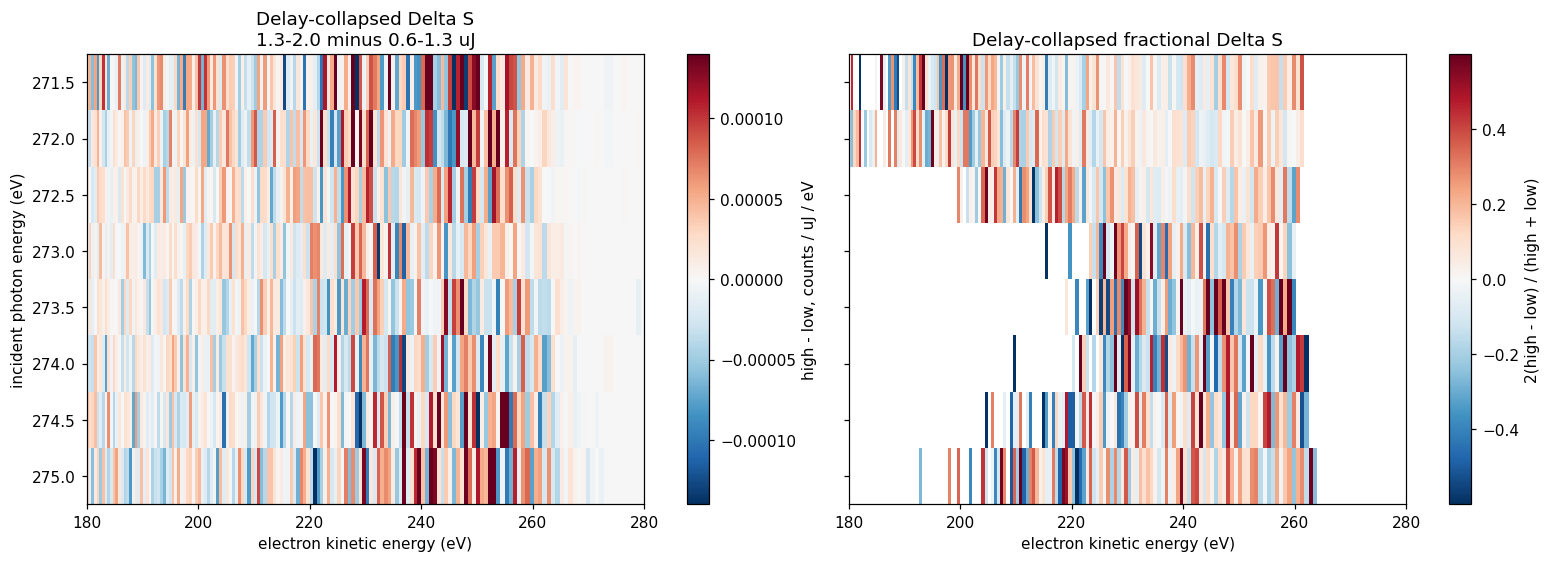

Plotted energies: [271.5 272.  272.5 273.  273.5 274.  274.5 275. ]
diff_vlim: 0.00013983547394355039


In [145]:
# --- Delay-collapsed high-low maps across incident photon energy ---

rows = [row for row in full_rows if row["usable"]]
rows.sort(key=lambda row: row["energy"])

if not rows:
    raise ValueError("No usable rows to plot")

energies = np.array([row["energy"] for row in rows], dtype=float)

difference_tof = np.vstack([row["diff"] for row in rows])
fractional_tof = np.vstack([row["frac"] for row in rows])
denominator_tof = np.vstack([
    row["high"]["spectrum"] + row["low"]["spectrum"]
    for row in rows
])

ke_edges, difference_ke = tof_map_to_ke_density(
    tof_edges_ref, difference_tof, TOF_RANGE
)

ke_widths = np.abs(np.diff(ke_edges))

_, fractional_density = tof_map_to_ke_density(
    tof_edges_ref, fractional_tof, TOF_RANGE
)
_, denominator_density = tof_map_to_ke_density(
    tof_edges_ref, denominator_tof, TOF_RANGE
)

# Undo density Jacobian for dimensionless fractional quantity.
fractional_ke = fractional_density * ke_widths[None, :]
denominator_ke = denominator_density * ke_widths[None, :]

fractional_ke[denominator_ke < FRAC_DENOM_MIN] = np.nan
fractional_ke[np.abs(fractional_ke) > 2.0] = np.nan

finite = difference_ke[np.isfinite(difference_ke)]
diff_vlim = float(np.nanpercentile(np.abs(finite), 99.0))
frac_vlim = 0.6

energy_edges = half_step_edges(energies)

diff_norm = TwoSlopeNorm(
    vmin=-diff_vlim,
    vcenter=0.0,
    vmax=diff_vlim,
)
frac_norm = TwoSlopeNorm(
    vmin=-frac_vlim,
    vcenter=0.0,
    vmax=frac_vlim,
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True,
    constrained_layout=True,
)

image_abs = axes[0].pcolormesh(
    ke_edges,
    energy_edges,
    difference_ke,
    shading="auto",
    cmap="RdBu_r",
    norm=diff_norm,
)
fig.colorbar(
    image_abs,
    ax=axes[0],
    label="high - low, counts / uJ / eV",
)

axes[0].set_title(
    f"Delay-collapsed Delta S\n"
    f"{HIGH_GMD_RANGE[0]}-{HIGH_GMD_RANGE[1]} minus "
    f"{LOW_GMD_RANGE[0]}-{LOW_GMD_RANGE[1]} uJ"
)
axes[0].set_xlabel("electron kinetic energy (eV)")
axes[0].set_ylabel("incident photon energy (eV)")

image_frac = axes[1].pcolormesh(
    ke_edges,
    energy_edges,
    fractional_ke,
    shading="auto",
    cmap="RdBu_r",
    norm=frac_norm,
)
fig.colorbar(
    image_frac,
    ax=axes[1],
    label="2(high - low) / (high + low)",
)

axes[1].set_title("Delay-collapsed fractional Delta S")
axes[1].set_xlabel("electron kinetic energy (eV)")

for axis in axes:
    axis.set_xlim(KE_XLIM)
    axis.set_ylim(np.nanmax(energy_edges), np.nanmin(energy_edges))
    axis.grid(False)

plt.show()

print("Plotted energies:", energies)
print("diff_vlim:", diff_vlim)

### KE integration

In [146]:
# --- Integrated KE-window traces with counting uncertainties ---

CANDIDATE_KE_WINDOWS = [
    (190, 200),
    (200, 210),
    (210, 220),
    (190, 210),
    (200, 220),
    (195, 215),
    (190, 220),
]

BACKGROUND_COMPARISON_KE_RANGE = (180, 190)

# With this scan only covering 271-275 eV, keep the baseline local.
# Adjust later if this turns out to eat into the feature.
#Change between datasets
BASELINE_ENERGY_RANGES = [(271.5, 272.0)]
# BASELINE_ENERGY_RANGES = [(275.5, 276)]

PEAK_ENERGY_WINDOW = (273.0, 275.0)
# PEAK_ENERGY_WINDOW = (274.0, 275.0)

REFERENCE_ENERGY_EV = 274.0
PEAK_KE_RANGE = (190, 220)



def ke_window_weights_for_tof_bins(tof_edges, ke_range):
    """Fractional overlap of each native calibrated TOF bin with a KE window."""
    ke_edges_local = tof_to_ke(tof_edges)

    lo = np.minimum(ke_edges_local[:-1], ke_edges_local[1:])
    hi = np.maximum(ke_edges_local[:-1], ke_edges_local[1:])
    width = hi - lo

    overlap = np.maximum(
        0.0,
        np.minimum(hi, ke_range[1]) - np.maximum(lo, ke_range[0]),
    )

    weights = np.zeros_like(width, dtype=float)
    good = np.isfinite(lo) & np.isfinite(hi) & (width > 0)
    weights[good] = overlap[good] / width[good]

    return weights


def integrate_group_with_uncertainty(group, tof_edges, ke_range):
    """Integrate counts/sum(GMD) and propagate Poisson count variance."""
    weights = ke_window_weights_for_tof_bins(tof_edges, ke_range)

    counts = np.asarray(group["counts"], dtype=float)
    sum_gmd = float(group["sum_gmd"])

    weighted_counts = float(np.nansum(weights * counts))
    variance_counts = float(
        np.nansum((weights ** 2) * np.maximum(counts, 0.0))
    )

    if sum_gmd <= 0:
        return np.nan, np.nan, weighted_counts

    value = weighted_counts / sum_gmd
    sigma = np.sqrt(variance_counts) / sum_gmd

    return value, sigma, weighted_counts


def build_window_traces(full_rows, ke_windows, *, use_only_usable=True):
    rows = [
        row for row in full_rows
        if row["usable"] or not use_only_usable
    ]
    rows.sort(key=lambda row: row["energy"])

    output = {
        "rows": rows,
        "energies": np.array([row["energy"] for row in rows], dtype=float),
        "delta": {},
        "sigma": {},
        "low": {},
        "high": {},
        "low_sigma": {},
        "high_sigma": {},
    }

    for ke_range in ke_windows:
        low_values = []
        high_values = []
        low_sigmas = []
        high_sigmas = []
        differences = []
        uncertainties = []

        for row in rows:
            low, sigma_low, _ = integrate_group_with_uncertainty(
                row["low"], tof_edges_ref, ke_range
            )
            high, sigma_high, _ = integrate_group_with_uncertainty(
                row["high"], tof_edges_ref, ke_range
            )

            low_values.append(low)
            high_values.append(high)
            low_sigmas.append(sigma_low)
            high_sigmas.append(sigma_high)
            differences.append(high - low)
            uncertainties.append(np.sqrt(sigma_low ** 2 + sigma_high ** 2))

        output["low"][ke_range] = np.array(low_values, dtype=float)
        output["high"][ke_range] = np.array(high_values, dtype=float)
        output["low_sigma"][ke_range] = np.array(low_sigmas, dtype=float)
        output["high_sigma"][ke_range] = np.array(high_sigmas, dtype=float)
        output["delta"][ke_range] = np.array(differences, dtype=float)
        output["sigma"][ke_range] = np.array(uncertainties, dtype=float)

    return output


def mask_energy_ranges(energies, ranges):
    mask = np.zeros_like(energies, dtype=bool)
    for lo, hi in ranges:
        mask |= (energies >= lo) & (energies <= hi)
    return mask


def weighted_baseline_mean(values, uncertainties, baseline_mask):
    values = np.asarray(values, dtype=float)
    uncertainties = np.asarray(uncertainties, dtype=float)

    good = (
        baseline_mask
        & np.isfinite(values)
        & np.isfinite(uncertainties)
        & (uncertainties > 0)
    )

    if np.count_nonzero(good) < 1:
        return np.nan, np.nan, np.nan, 0

    weights = 1.0 / uncertainties[good] ** 2
    mean = np.sum(weights * values[good]) / np.sum(weights)
    mean_error = np.sqrt(1.0 / np.sum(weights))
    rms = np.sqrt(np.nanmean((values[good] - mean) ** 2))

    return mean, mean_error, rms, int(np.count_nonzero(good))


def nearest_energy_index(energies, target):
    energies = np.asarray(energies, dtype=float)
    return int(np.nanargmin(np.abs(energies - target)))


candidate_traces = build_window_traces(
    full_rows,
    CANDIDATE_KE_WINDOWS + [BACKGROUND_COMPARISON_KE_RANGE],
    use_only_usable=True,
)

incident_energies = candidate_traces["energies"]
baseline_mask = mask_energy_ranges(
    incident_energies,
    BASELINE_ENERGY_RANGES,
)

print("Trace energies:", incident_energies)
print("Baseline energies:", incident_energies[baseline_mask])

Trace energies: [271.5 272.  272.5 273.  273.5 274.  274.5 275. ]
Baseline energies: [271.5 272. ]


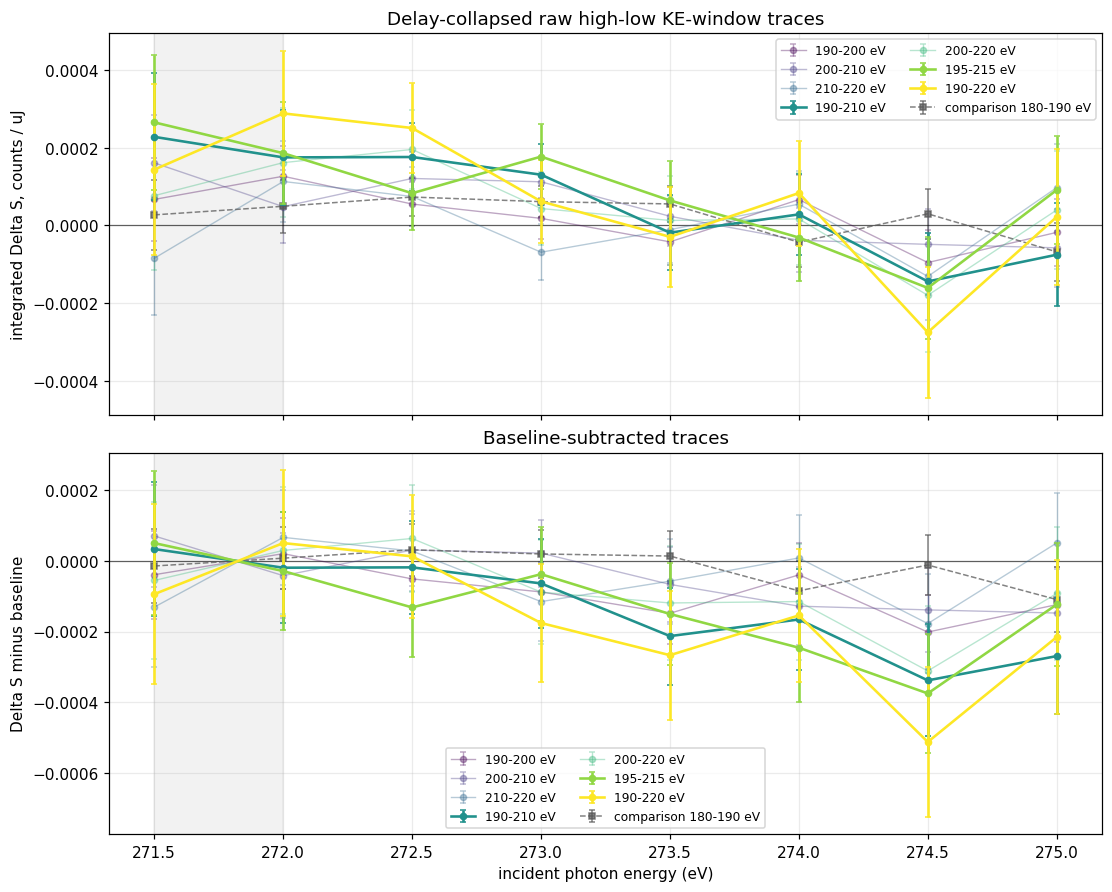

In [147]:
# --- Plot integrated candidate-window traces ---

fig, axes = plt.subplots(
    2, 1, figsize=(10, 8), sharex=True, constrained_layout=True
)

highlighted_windows = [(190, 220), (190, 210), (195, 215)]
colours = plt.get_cmap("viridis")(np.linspace(0, 1, len(CANDIDATE_KE_WINDOWS)))

baseline_results = {}

for colour, ke_range in zip(colours, CANDIDATE_KE_WINDOWS):
    values = candidate_traces["delta"][ke_range]
    uncertainties = candidate_traces["sigma"][ke_range]

    off_mean, off_mean_error, off_rms, n_off = weighted_baseline_mean(
        values, uncertainties, baseline_mask
    )

    zeroed = values - off_mean
    zeroed_error = np.sqrt(uncertainties ** 2 + off_mean_error ** 2)

    baseline_results[ke_range] = {
        "off_mean": off_mean,
        "off_mean_err": off_mean_error,
        "off_rms": off_rms,
        "n_off": n_off,
        "zeroed": zeroed,
        "zeroed_err": zeroed_error,
    }

    highlighted = ke_range in highlighted_windows
    alpha = 1.0 if highlighted else 0.35
    linewidth = 1.7 if highlighted else 0.9
    zorder = 5 if highlighted else 2

    label = f"{ke_range[0]}-{ke_range[1]} eV"

    axes[0].errorbar(
        incident_energies, values, yerr=uncertainties, fmt="o-", ms=4, lw=linewidth,
        capsize=2, color=colour, alpha=alpha, zorder=zorder, label=label
    )

    axes[1].errorbar(
        incident_energies, zeroed, yerr=zeroed_error, fmt="o-", ms=4, lw=linewidth,
        capsize=2, color=colour, alpha=alpha, zorder=zorder, label=label
    )

comparison = candidate_traces["delta"][BACKGROUND_COMPARISON_KE_RANGE]
comparison_sigma = candidate_traces["sigma"][BACKGROUND_COMPARISON_KE_RANGE]

comparison_mean, comparison_mean_error, comparison_rms, comparison_n = (
    weighted_baseline_mean(comparison, comparison_sigma, baseline_mask)
)

comparison_zeroed = comparison - comparison_mean
comparison_zeroed_error = np.sqrt(comparison_sigma ** 2 + comparison_mean_error ** 2)

comp_label = (
    f"comparison {BACKGROUND_COMPARISON_KE_RANGE[0]}-"
    f"{BACKGROUND_COMPARISON_KE_RANGE[1]} eV"
)

axes[0].errorbar(
    incident_energies, comparison, yerr=comparison_sigma, fmt="s--", ms=4, lw=1.0,
    capsize=2, color="0.35", alpha=0.75, label=comp_label
)

axes[1].errorbar(
    incident_energies, comparison_zeroed, yerr=comparison_zeroed_error, fmt="s--", ms=4, lw=1.0,
    capsize=2, color="0.35", alpha=0.75, label=comp_label
)

for axis in axes:
    axis.axhline(0.0, color="k", lw=0.8, alpha=0.6)

    for lo, hi in BASELINE_ENERGY_RANGES:
        axis.axvspan(lo, hi, color="0.8", alpha=0.25)

    axis.grid(alpha=0.25)
    axis.legend(fontsize=8, ncols=2)

axes[0].set_ylabel("integrated Delta S, counts / uJ")
axes[0].set_title("Delay-collapsed raw high-low KE-window traces")

axes[1].set_xlabel("incident photon energy (eV)")
axes[1].set_ylabel("Delta S minus baseline")
axes[1].set_title("Baseline-subtracted traces")

plt.show()

Baseline subtraction: False
Peak maximum        : 274.000 eV
Peak value          : 8.34469e-05 +/- 0.000135 counts/uJ
Positive centroid   : 273.762 eV
RMS width           : 0.667 eV
Approximate FWHM    : 1.000 eV


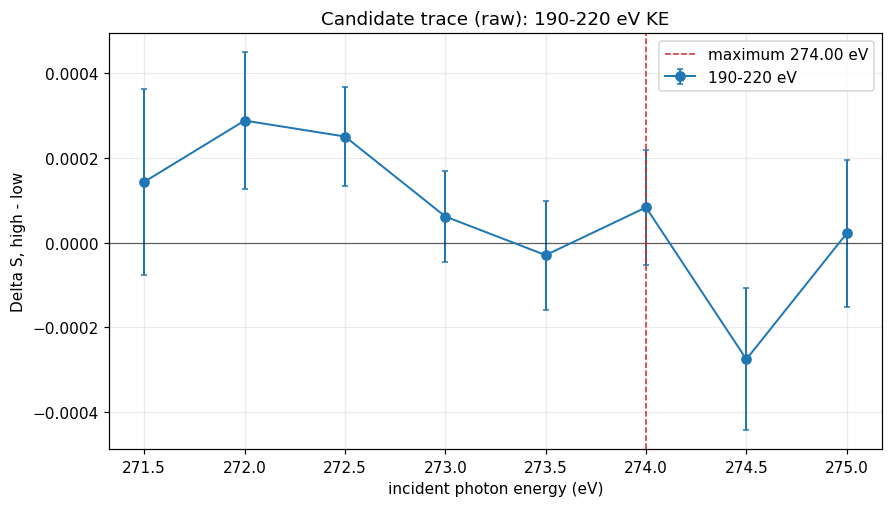

In [148]:
# --- Focused plot for the selected KE window, optional baseline subtraction ---

SUBTRACT_CANDIDATE_BASELINE = False  # set False to plot raw high-low Delta S

values = candidate_traces["delta"][PEAK_KE_RANGE]
uncertainties = candidate_traces["sigma"][PEAK_KE_RANGE]
baseline = baseline_results[PEAK_KE_RANGE]

if SUBTRACT_CANDIDATE_BASELINE:
    plotted = values - baseline["off_mean"]
    plotted_error = np.sqrt(
        uncertainties ** 2 + baseline["off_mean_err"] ** 2
    )
    y_label = "Delta S minus weighted baseline"
    title_suffix = "baseline-subtracted"
else:
    plotted = values.copy()
    plotted_error = uncertainties.copy()
    y_label = "Delta S, high - low"
    title_suffix = "raw"

peak_mask = (
    np.isfinite(incident_energies)
    & np.isfinite(plotted)
    & (incident_energies >= PEAK_ENERGY_WINDOW[0])
    & (incident_energies <= PEAK_ENERGY_WINDOW[1])
)

if np.count_nonzero(peak_mask) < 2:
    raise ValueError("Not enough points in PEAK_ENERGY_WINDOW")

peak_energies = incident_energies[peak_mask]
peak_values = plotted[peak_mask]
peak_errors = plotted_error[peak_mask]

maximum_index = int(np.nanargmax(peak_values))
peak_energy = peak_energies[maximum_index]
peak_value = peak_values[maximum_index]
peak_sigma = peak_errors[maximum_index]

positive_weights = np.maximum(peak_values, 0.0)

if np.nansum(positive_weights) > 0:
    centroid = (
        np.nansum(peak_energies * positive_weights)
        / np.nansum(positive_weights)
    )
    rms_width = np.sqrt(
        np.nansum(positive_weights * (peak_energies - centroid) ** 2)
        / np.nansum(positive_weights)
    )
else:
    centroid = np.nan
    rms_width = np.nan

above_half_maximum = peak_values >= 0.5 * peak_value

if np.count_nonzero(above_half_maximum) >= 2:
    fwhm_approx = (
        np.nanmax(peak_energies[above_half_maximum])
        - np.nanmin(peak_energies[above_half_maximum])
    )
else:
    fwhm_approx = np.nan

print("Baseline subtraction:", SUBTRACT_CANDIDATE_BASELINE)
if SUBTRACT_CANDIDATE_BASELINE:
    print(f"Baseline offset     : {baseline['off_mean']:.6g} +/- {baseline['off_mean_err']:.3g}")
    print(f"Baseline RMS        : {baseline['off_rms']:.3g}")

print(f"Peak maximum        : {peak_energy:.3f} eV")
print(f"Peak value          : {peak_value:.6g} +/- {peak_sigma:.3g} counts/uJ")
print(f"Positive centroid   : {centroid:.3f} eV")
print(f"RMS width           : {rms_width:.3f} eV")
print(f"Approximate FWHM    : {fwhm_approx:.3f} eV")

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)

ax.errorbar(
    incident_energies,
    plotted,
    yerr=plotted_error,
    fmt="o-",
    lw=1.3,
    capsize=2,
    label=f"{PEAK_KE_RANGE[0]}-{PEAK_KE_RANGE[1]} eV",
)

ax.axhline(0.0, color="k", lw=0.8, alpha=0.6)

ax.axvline(
    peak_energy,
    color="tab:red",
    lw=1.0,
    ls="--",
    label=f"maximum {peak_energy:.2f} eV",
)

if SUBTRACT_CANDIDATE_BASELINE:
    for lo, hi in BASELINE_ENERGY_RANGES:
        ax.axvspan(lo, hi, color="0.8", alpha=0.25)

ax.set_xlabel("incident photon energy (eV)")
ax.set_ylabel(y_label)
ax.set_title(
    f"Candidate trace ({title_suffix}): "
    f"{PEAK_KE_RANGE[0]}-{PEAK_KE_RANGE[1]} eV KE"
)
ax.grid(alpha=0.25)
ax.legend()

plt.show()

### Debugging

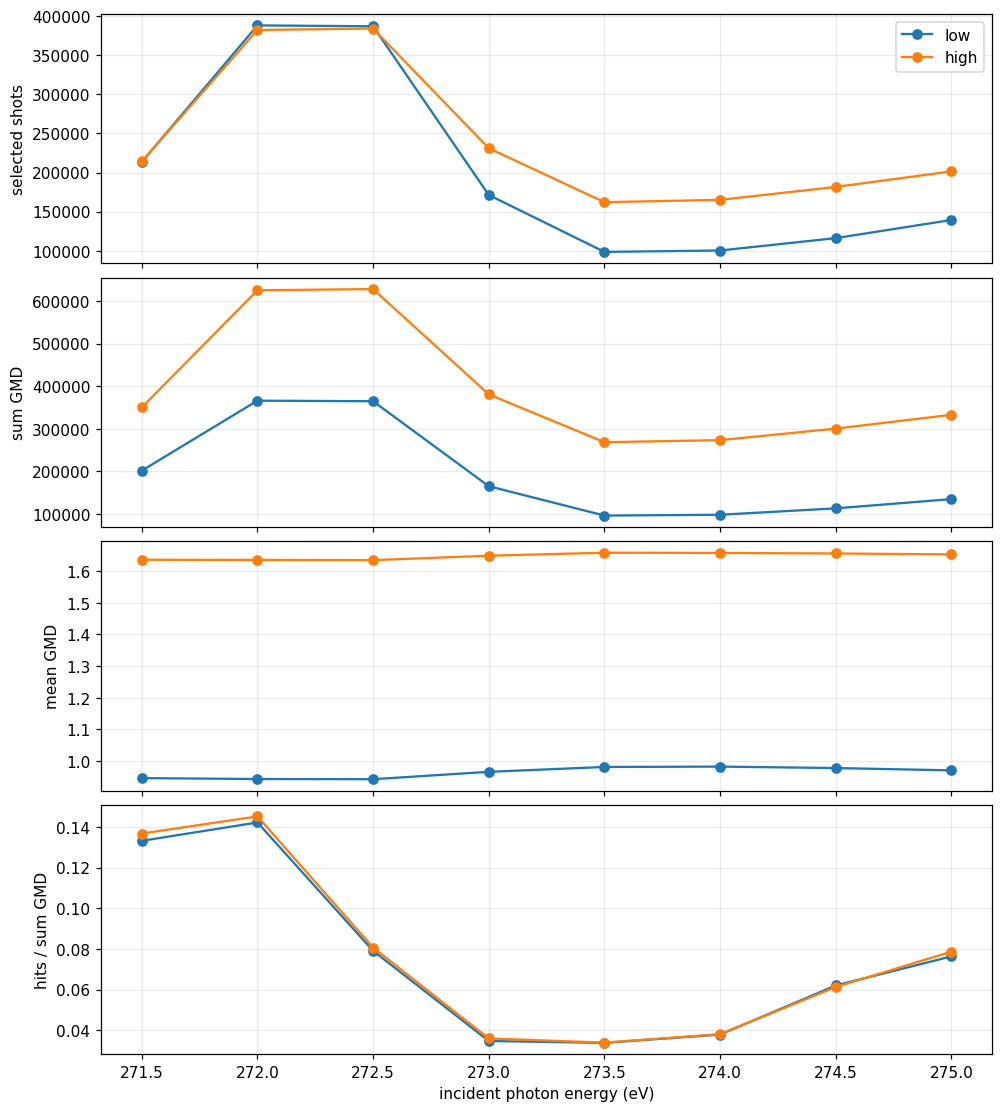

In [149]:
# --- Per-energy statistics for the selected low/high groups ---

stats_rows = []

for row in full_rows:
    low = row["low"]
    high = row["high"]

    stats_rows.append({
        "energy": row["energy"],
        "low_shots": low["shots"],
        "high_shots": high["shots"],
        "low_sum_gmd": low["sum_gmd"],
        "high_sum_gmd": high["sum_gmd"],
        "low_hits": low["hits"],
        "high_hits": high["hits"],
        "low_mean_gmd": low["sum_gmd"] / low["shots"],
        "high_mean_gmd": high["sum_gmd"] / high["shots"],
        "low_hits_per_gmd": low["hits"] / low["sum_gmd"],
        "high_hits_per_gmd": high["hits"] / high["sum_gmd"],
    })

energies = np.array([r["energy"] for r in stats_rows])

fig, axes = plt.subplots(4, 1, figsize=(9, 10), sharex=True, constrained_layout=True)

axes[0].plot(energies, [r["low_shots"] for r in stats_rows], "o-", label="low")
axes[0].plot(energies, [r["high_shots"] for r in stats_rows], "o-", label="high")
axes[0].set_ylabel("selected shots")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(energies, [r["low_sum_gmd"] for r in stats_rows], "o-", label="low")
axes[1].plot(energies, [r["high_sum_gmd"] for r in stats_rows], "o-", label="high")
axes[1].set_ylabel("sum GMD")
axes[1].grid(alpha=0.25)

axes[2].plot(energies, [r["low_mean_gmd"] for r in stats_rows], "o-", label="low")
axes[2].plot(energies, [r["high_mean_gmd"] for r in stats_rows], "o-", label="high")
axes[2].set_ylabel("mean GMD")
axes[2].grid(alpha=0.25)

axes[3].plot(energies, [r["low_hits_per_gmd"] for r in stats_rows], "o-", label="low")
axes[3].plot(energies, [r["high_hits_per_gmd"] for r in stats_rows], "o-", label="high")
axes[3].set_ylabel("hits / sum GMD")
axes[3].set_xlabel("incident photon energy (eV)")
axes[3].grid(alpha=0.25)

plt.show()

In [150]:
# --- Diagnose zero selected shots in current low/high bands ---

print("Current GMD bands:")
print("  LOW :", LOW_GMD_RANGE)
print("  HIGH:", HIGH_GMD_RANGE)

for row in full_rows:
    low = row["low"]
    high = row["high"]

    flags = []
    if low["shots"] == 0:
        flags.append("LOW_ZERO_SHOTS")
    if high["shots"] == 0:
        flags.append("HIGH_ZERO_SHOTS")
    if low["sum_gmd"] == 0:
        flags.append("LOW_ZERO_GMD")
    if high["sum_gmd"] == 0:
        flags.append("HIGH_ZERO_GMD")

    print(
        f"{row['energy']:6.1f} eV  usable={row['usable']}  "
        f"low shots={low['shots']:8d}, sumGMD={low['sum_gmd']:10.3g}, hits={low['hits']:8d}  "
        f"high shots={high['shots']:8d}, sumGMD={high['sum_gmd']:10.3g}, hits={high['hits']:8d}  "
        f"{' '.join(flags)}"
    )

Current GMD bands:
  LOW : (0.6, 1.3)
  HIGH: (1.3, 2.0)
 271.5 eV  usable=True  low shots=  213518, sumGMD=  2.02e+05, hits=   26893  high shots=  214108, sumGMD=   3.5e+05, hits=   47890  
 272.0 eV  usable=True  low shots=  388207, sumGMD=  3.66e+05, hits=   52061  high shots=  382330, sumGMD=  6.25e+05, hits=   90766  
 272.5 eV  usable=True  low shots=  387066, sumGMD=  3.65e+05, hits=   28836  high shots=  384219, sumGMD=  6.28e+05, hits=   50638  
 273.0 eV  usable=True  low shots=  171314, sumGMD=  1.65e+05, hits=    5735  high shots=  231089, sumGMD=  3.81e+05, hits=   13680  
 273.5 eV  usable=True  low shots=   98474, sumGMD=  9.66e+04, hits=    3260  high shots=  162082, sumGMD=  2.69e+05, hits=    9102  
 274.0 eV  usable=True  low shots=  100254, sumGMD=  9.85e+04, hits=    3725  high shots=  165046, sumGMD=  2.74e+05, hits=   10399  
 274.5 eV  usable=True  low shots=  116069, sumGMD=  1.13e+05, hits=    7033  high shots=  181541, sumGMD=  3.01e+05, hits=   18396  
 275.

In [151]:
# --- Diagnose the row with zero low/high shots ---

bad_rows = [
    row for row in full_rows
    if row["low"]["shots"] == 0 or row["high"]["shots"] == 0
]

for row in bad_rows:
    print("\n==", row["energy"], "eV ==")
    print("aggregate:", row["path"])
    print("source   :", row["source_h5"])
    print("trim     :", row["trim_start"], row["trim_end"])
    print("z_edges  :", row["z_edges"][0], row["z_edges"][-1], "n=", len(row["z_edges"]) - 1)

    with h5py.File(row["source_h5"], "r") as handle:
        print("source keys:", list(handle.keys()))
        print("gmd shape:", handle["gmd"].shape)
        print("z shape  :", handle["z"].shape)
        print("tofs_e shape:", handle["tofs_e"].shape if "tofs_e" in handle else "missing")

        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=row["trim_start"],
            trim_end=row["trim_end"],
        )

        gmd = handle["gmd"][:][keep]
        z = handle["z"][:][keep]

    z_edges = np.asarray(row["z_edges"], dtype=float)
    delay_bin = np.searchsorted(z_edges, z, side="right") - 1

    valid_delay = (
        np.isfinite(gmd)
        & np.isfinite(z)
        & (delay_bin >= 0)
        & (delay_bin < len(z_edges) - 1)
    )

    print("kept trains:", keep.sum())
    print("finite gmd shots:", np.count_nonzero(np.isfinite(gmd)))
    print("finite z shots  :", np.count_nonzero(np.isfinite(z)))
    print("valid delay shots:", np.count_nonzero(valid_delay))

    if np.count_nonzero(np.isfinite(gmd)) > 0:
        print("gmd percentiles all finite:")
        print(np.nanpercentile(gmd[np.isfinite(gmd)], [0, 1, 10, 50, 90, 99, 100]))

    if np.count_nonzero(valid_delay) > 0:
        gv = gmd[valid_delay]
        zv = z[valid_delay]
        print("gmd percentiles valid delay:")
        print(np.nanpercentile(gv, [0, 1, 10, 50, 90, 99, 100]))
        print("z percentiles valid delay:")
        print(np.nanpercentile(zv, [0, 1, 10, 50, 90, 99, 100]))

        low_count = np.count_nonzero(
            (gv >= LOW_GMD_RANGE[0]) & (gv < LOW_GMD_RANGE[1])
        )
        high_count = np.count_nonzero(
            (gv >= HIGH_GMD_RANGE[0]) & (gv < HIGH_GMD_RANGE[1])
        )

        print("low-band valid shots :", low_count)
        print("high-band valid shots:", high_count)
    else:
        print("No valid-delay shots. This points to z_edges/source mismatch or bad aggregate metadata.")

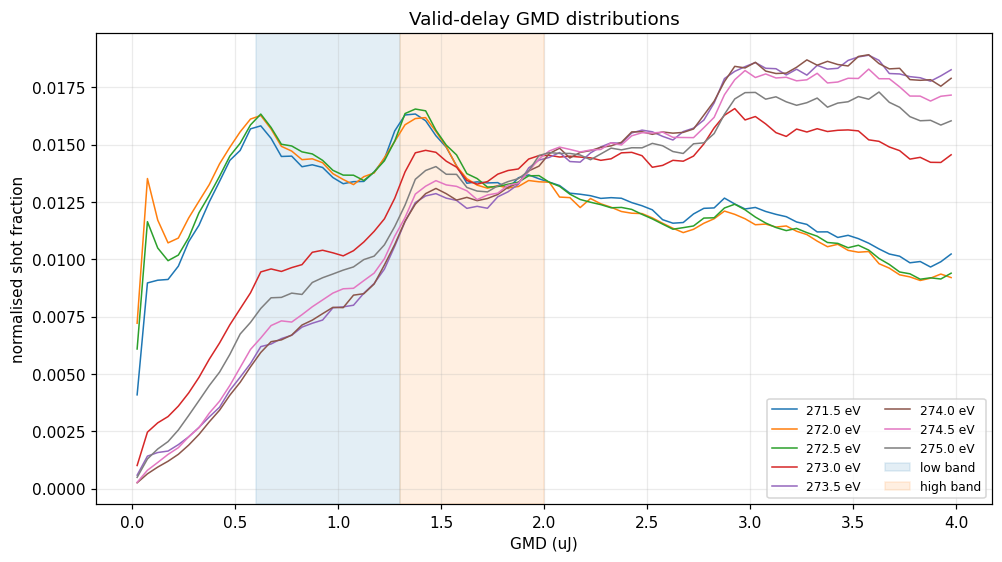

In [152]:
# --- GMD distributions across loaded energies ---

GMD_HIST_EDGES = np.linspace(0, 4.0, 81)

def valid_delay_gmd_values(source_h5, z_edges, *, trim_start=0, trim_end=0, chunk_trains=1000):
    vals = []

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=trim_start,
            trim_end=trim_end,
        )

        n_trains = handle["gmd"].shape[0]
        z_edges = np.asarray(z_edges, dtype=float)

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]
            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep]
            z = handle["z"][start:stop][row_keep]

            delay_bin = np.searchsorted(z_edges, z, side="right") - 1
            valid = (
                np.isfinite(gmd)
                & np.isfinite(z)
                & (delay_bin >= 0)
                & (delay_bin < len(z_edges) - 1)
            )

            vals.append(gmd[valid])

    return np.concatenate(vals) if vals else np.array([])


fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)

for row in full_rows:
    gmd_vals = valid_delay_gmd_values(
        row["source_h5"],
        row["z_edges"],
        trim_start=row["trim_start"],
        trim_end=row["trim_end"],
        chunk_trains=CHUNK_TRAINS,
    )

    hist, edges = np.histogram(gmd_vals, bins=GMD_HIST_EDGES)
    centres = 0.5 * (edges[:-1] + edges[1:])

    if hist.sum() > 0:
        hist = hist / hist.sum()

    ax.plot(centres, hist, lw=1.0, label=f"{row['energy']:.1f} eV")

ax.axvspan(*LOW_GMD_RANGE, color="tab:blue", alpha=0.12, label="low band")
ax.axvspan(*HIGH_GMD_RANGE, color="tab:orange", alpha=0.12, label="high band")

ax.set_xlabel("GMD (uJ)")
ax.set_ylabel("normalised shot fraction")
ax.set_title("Valid-delay GMD distributions")
ax.grid(alpha=0.25)
ax.legend(fontsize=8, ncols=2)

plt.show()

### Fitting nonlinearity

In [153]:
# --- Multi-bin GMD dependence in one KE window ---

GMD_RESPONSE_KE_RANGE = (190, 220)
GMD_RESPONSE_EDGES = np.arange(0.6, 2.0 + 0.2, 0.2)
GMD_RESPONSE_MIN_SHOTS = 1000


def row_trim_values(row):
    if "trim_start" in row and "trim_end" in row:
        return int(row["trim_start"]), int(row["trim_end"])

    # Clean static notebook fallback.
    if "path" in row and "load_aggregates_etof" in globals():
        agg = load_aggregates_etof(row["path"])
        return (
            int(agg.metadata.get("trim_start", 0) or 0),
            int(agg.metadata.get("trim_end", 0) or 0),
        )

    return 0, 0


def ke_window_weights_for_tof_bins(tof_edges, ke_range):
    ke_edges = tof_to_ke(tof_edges)

    lo = np.minimum(ke_edges[:-1], ke_edges[1:])
    hi = np.maximum(ke_edges[:-1], ke_edges[1:])
    width = hi - lo

    overlap = np.maximum(
        0.0,
        np.minimum(hi, ke_range[1]) - np.maximum(lo, ke_range[0]),
    )

    weights = np.zeros_like(width, dtype=float)
    good = np.isfinite(lo) & np.isfinite(hi) & (width > 0)
    weights[good] = overlap[good] / width[good]

    return weights


def gmd_binned_ke_yield_for_row(
    row,
    gmd_edges,
    ke_range,
    *,
    tof_edges=None,
    chunk_trains=1000,
    require_valid_delay_if_present=True,
):
    source_h5 = Path(row["source_h5"])
    tof_edges = tof_edges_ref if tof_edges is None else np.asarray(tof_edges, dtype=float)
    gmd_edges = np.asarray(gmd_edges, dtype=float)

    weights = ke_window_weights_for_tof_bins(tof_edges, ke_range)
    n_gmd = len(gmd_edges) - 1

    shots = np.zeros(n_gmd, dtype=np.int64)
    sum_gmd = np.zeros(n_gmd, dtype=float)
    counts = np.zeros(n_gmd, dtype=float)
    count_variance = np.zeros(n_gmd, dtype=float)

    trim_start, trim_end = row_trim_values(row)

    use_delay = (
        require_valid_delay_if_present
        and ("z_edges" in row)
        and row["z_edges"] is not None
    )
    if use_delay:
        z_edges = np.asarray(row["z_edges"], dtype=float)
        n_delay = len(z_edges) - 1

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=trim_start,
            trim_end=trim_end,
        )

        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep]
            tofs = handle["tofs_e"][start:stop][row_keep]

            valid = np.isfinite(gmd)

            if use_delay:
                z = handle["z"][start:stop][row_keep]
                delay_bin = np.searchsorted(z_edges, z, side="right") - 1
                valid &= (
                    np.isfinite(z)
                    & (delay_bin >= 0)
                    & (delay_bin < n_delay)
                )

            gmd_flat = gmd.reshape(-1)
            tofs_flat = tofs.reshape(-1, tofs.shape[-1])
            valid_flat = valid.reshape(-1)

            gmd_bin = np.searchsorted(gmd_edges, gmd_flat, side="right") - 1

            for i in range(n_gmd):
                selected = valid_flat & (gmd_bin == i)
                if not selected.any():
                    continue

                selected_gmd = gmd_flat[selected]
                hits = tofs_flat[selected].reshape(-1)
                hits = hits[np.isfinite(hits) & (hits > 0)]

                hist, _ = np.histogram(hits, bins=tof_edges)

                shots[i] += int(np.count_nonzero(selected))
                sum_gmd[i] += float(np.nansum(selected_gmd))
                counts[i] += float(np.nansum(weights * hist))
                count_variance[i] += float(np.nansum((weights ** 2) * hist))

    with np.errstate(invalid="ignore", divide="ignore"):
        mean_gmd = sum_gmd / shots
        yield_per_shot = counts / shots
        yield_per_gmd = counts / sum_gmd
        sigma_yield_per_gmd = np.sqrt(count_variance) / sum_gmd

    good = (
        np.isfinite(mean_gmd)
        & np.isfinite(yield_per_gmd)
        & np.isfinite(sigma_yield_per_gmd)
        & (shots >= GMD_RESPONSE_MIN_SHOTS)
        & (sum_gmd > 0)
        & (sigma_yield_per_gmd > 0)
    )

    return {
        "energy": row["energy"],
        "gmd_edges": gmd_edges,
        "mean_gmd": mean_gmd,
        "shots": shots,
        "sum_gmd": sum_gmd,
        "counts": counts,
        "yield_per_shot": yield_per_shot,
        "yield_per_gmd": yield_per_gmd,
        "sigma_yield_per_gmd": sigma_yield_per_gmd,
        "good": good,
    }


def fit_yield_over_gmd_slope(diag):
    x = diag["mean_gmd"]
    y = diag["yield_per_gmd"]
    s = diag["sigma_yield_per_gmd"]
    good = diag["good"]

    if np.count_nonzero(good) < 3:
        return {
            "energy": diag["energy"],
            "a": np.nan,
            "b": np.nan,
            "sigma_a": np.nan,
            "sigma_b": np.nan,
            "n": int(np.count_nonzero(good)),
        }

    coeff, cov = np.polyfit(
        x[good],
        y[good],
        deg=1,
        w=1.0 / s[good],
        cov=True,
    )

    b, a = coeff
    sigma_b, sigma_a = np.sqrt(np.diag(cov))

    return {
        "energy": diag["energy"],
        "a": a,
        "b": b,
        "sigma_a": sigma_a,
        "sigma_b": sigma_b,
        "n": int(np.count_nonzero(good)),
    }

In [154]:
# --- Compute GMD response curves for every photon energy ---

gmd_response_rows = []
gmd_response_fits = []

for row in full_rows:
    if not row.get("usable", True):
        continue

    print(f"Processing {row['energy']:.1f} eV")

    diag = gmd_binned_ke_yield_for_row(
        row,
        GMD_RESPONSE_EDGES,
        GMD_RESPONSE_KE_RANGE,
        tof_edges=tof_edges_ref,
        chunk_trains=CHUNK_TRAINS,
    )

    fit = fit_yield_over_gmd_slope(diag)

    gmd_response_rows.append(diag)
    gmd_response_fits.append(fit)

print("Done.")

Processing 271.5 eV
Processing 272.0 eV
Processing 272.5 eV
Processing 273.0 eV
Processing 273.5 eV
Processing 274.0 eV
Processing 274.5 eV
Processing 275.0 eV
Done.


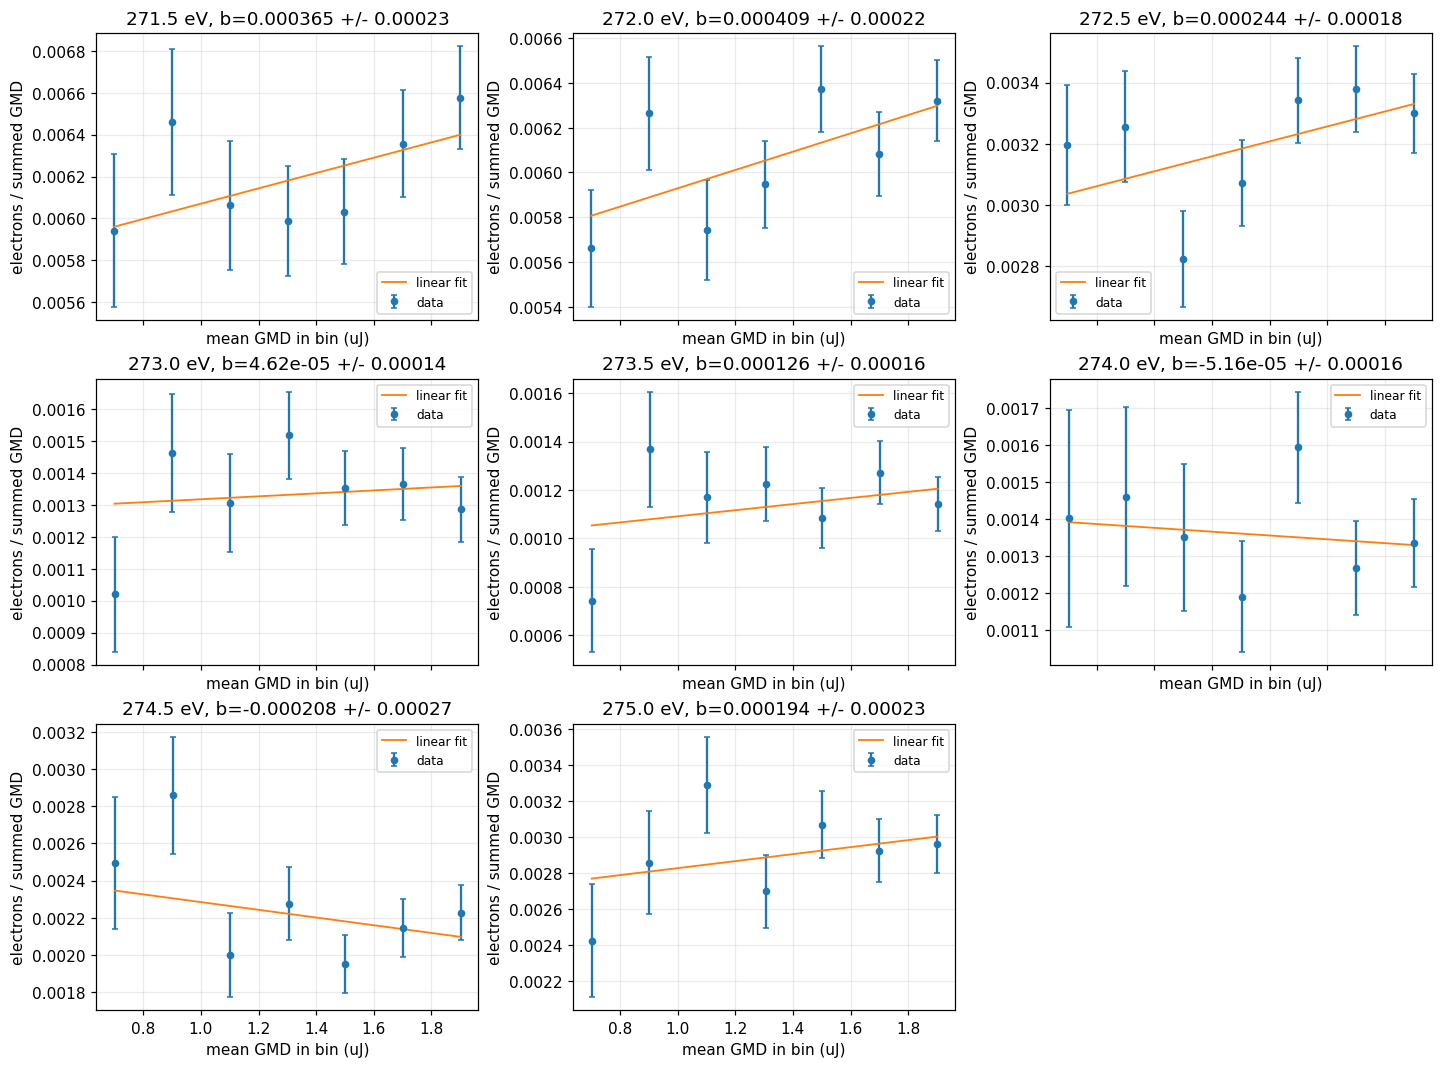

In [155]:
# --- Plot Y/G versus GMD for all photon energies ---

n = len(gmd_response_rows)
n_cols = 3
n_rows = int(np.ceil(n / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(13, 3.2 * n_rows),
    sharex=True,
    sharey=False,
    constrained_layout=True,
)

axes = np.ravel(axes)

for ax, diag, fit in zip(axes, gmd_response_rows, gmd_response_fits):
    good = diag["good"]

    ax.errorbar(
        diag["mean_gmd"][good],
        diag["yield_per_gmd"][good],
        yerr=diag["sigma_yield_per_gmd"][good],
        fmt="o",
        ms=4,
        capsize=2,
        label="data",
    )

    if np.isfinite(fit["b"]):
        xfit = np.linspace(
            np.nanmin(diag["mean_gmd"][good]),
            np.nanmax(diag["mean_gmd"][good]),
            100,
        )
        yfit = fit["a"] + fit["b"] * xfit
        ax.plot(xfit, yfit, "-", lw=1.2, label="linear fit")

    ax.set_title(
        f"{diag['energy']:.1f} eV, "
        f"b={fit['b']:.3g} +/- {fit['sigma_b']:.2g}"
    )
    ax.set_xlabel("mean GMD in bin (uJ)")
    ax.set_ylabel("electrons / summed GMD")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

for ax in axes[len(gmd_response_rows):]:
    ax.set_visible(False)

plt.show()

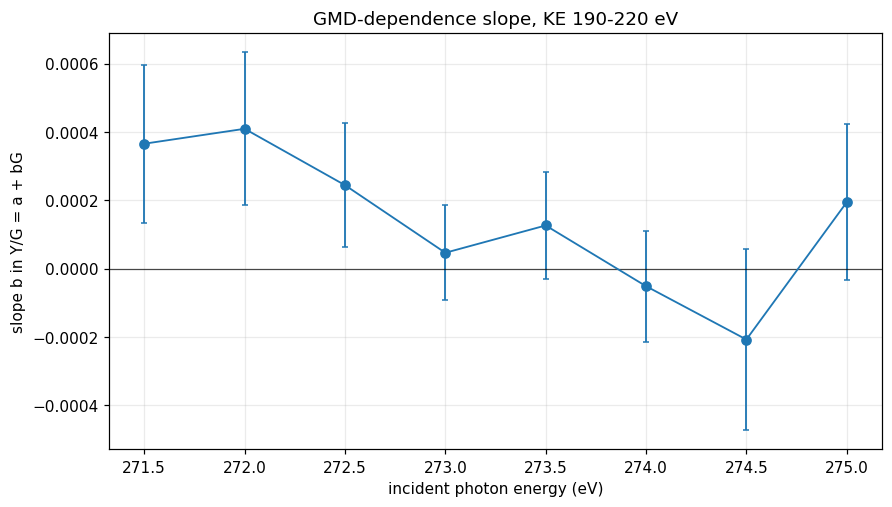

energy      b              sigma_b        n_bins
 271.50   0.000365454   0.000232    7
 272.00   0.000409144   0.000224    7
 272.50   0.000244138   0.000181    7
 273.00   4.61954e-05   0.000139    7
 273.50   0.000126148   0.000158    7
 274.00  -5.15628e-05   0.000162    7
 274.50  -0.000207743   0.000266    7
 275.00   0.000194193   0.000229    7


In [156]:
# --- Nonlinear slope b(hnu) ---

fit_energy = np.array([fit["energy"] for fit in gmd_response_fits], dtype=float)
fit_b = np.array([fit["b"] for fit in gmd_response_fits], dtype=float)
fit_sigma_b = np.array([fit["sigma_b"] for fit in gmd_response_fits], dtype=float)
fit_n = np.array([fit["n"] for fit in gmd_response_fits], dtype=int)

good = (
    np.isfinite(fit_energy)
    & np.isfinite(fit_b)
    & np.isfinite(fit_sigma_b)
    & (fit_sigma_b > 0)
)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)

ax.errorbar(
    fit_energy[good],
    fit_b[good],
    yerr=fit_sigma_b[good],
    fmt="o-",
    capsize=2,
    lw=1.2,
)

ax.axhline(0.0, color="k", lw=0.8, alpha=0.7)

ax.set_xlabel("incident photon energy (eV)")
ax.set_ylabel("slope b in Y/G = a + bG")
ax.set_title(
    f"GMD-dependence slope, KE {GMD_RESPONSE_KE_RANGE[0]}-"
    f"{GMD_RESPONSE_KE_RANGE[1]} eV"
)
ax.grid(alpha=0.25)

plt.show()

print("energy      b              sigma_b        n_bins")
for energy, b, sb, nbin in zip(fit_energy, fit_b, fit_sigma_b, fit_n):
    print(f"{energy:7.2f}  {b: .6g}  {sb: .3g}  {nbin:3d}")

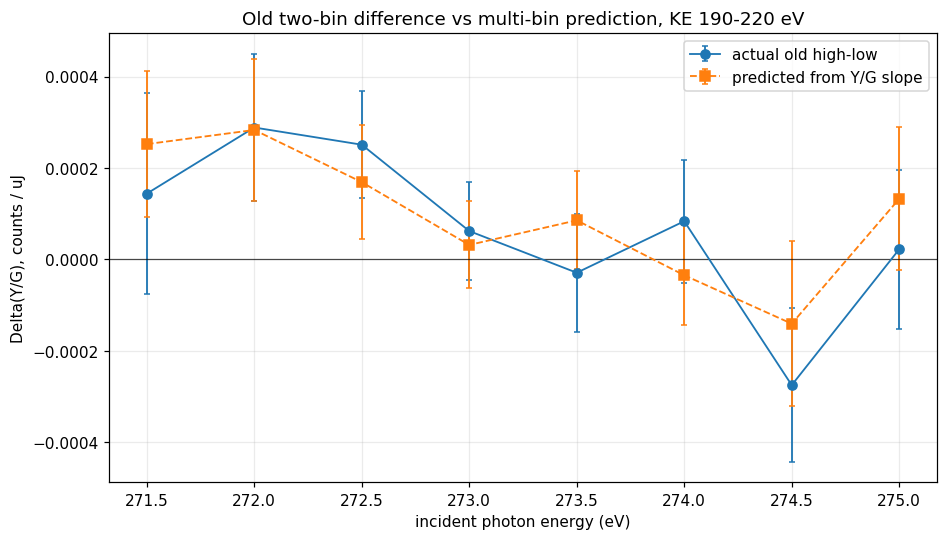

energy   actual_delta   actual_sigma   predicted_delta   predicted_sigma   <G>low   <G>high
271.50   0.000143773   0.00022   0.000252099   0.00016   0.946   1.636
272.00   0.000288476   0.000161   0.00028312   0.000155   0.943   1.635
272.50   0.00025084   0.000117   0.000168929   0.000125   0.943   1.634
273.00   6.19151e-05   0.000107   3.15365e-05   9.5e-05   0.966   1.649
273.50  -2.92824e-05   0.000129   8.53742e-05   0.000107   0.981   1.658
274.00   8.34469e-05   0.000135  -3.47981e-05   0.00011   0.982   1.657
274.50  -0.000275201   0.000168  -0.000140805   0.00018   0.978   1.656
275.00   2.21083e-05   0.000174   0.000132469   0.000156   0.970   1.653


In [157]:
# --- Compare fitted multi-bin prediction to original low-high difference ---

COMPARE_KE_RANGE = GMD_RESPONSE_KE_RANGE


def integrated_low_high_delta_for_row(row, ke_range):
    low_value, low_sigma, _ = integrate_group_with_uncertainty(
        row["low"],
        tof_edges_ref,
        ke_range,
    )
    high_value, high_sigma, _ = integrate_group_with_uncertainty(
        row["high"],
        tof_edges_ref,
        ke_range,
    )

    delta = high_value - low_value
    sigma = np.sqrt(low_sigma ** 2 + high_sigma ** 2)

    mean_g_low = row["low"]["sum_gmd"] / row["low"]["shots"]
    mean_g_high = row["high"]["sum_gmd"] / row["high"]["shots"]

    return {
        "actual_delta": delta,
        "actual_sigma": sigma,
        "mean_g_low": mean_g_low,
        "mean_g_high": mean_g_high,
        "delta_mean_g": mean_g_high - mean_g_low,
    }


fit_by_energy = {
    float(fit["energy"]): fit
    for fit in gmd_response_fits
}

rows_by_energy = {
    float(row["energy"]): row
    for row in full_rows
    if row.get("usable", True)
}

comparison_rows = []

for energy in sorted(set(fit_by_energy) & set(rows_by_energy)):
    fit = fit_by_energy[energy]
    row = rows_by_energy[energy]

    old = integrated_low_high_delta_for_row(row, COMPARE_KE_RANGE)

    predicted_delta = fit["b"] * old["delta_mean_g"]
    predicted_sigma = fit["sigma_b"] * abs(old["delta_mean_g"])

    comparison_rows.append({
        "energy": energy,
        "actual_delta": old["actual_delta"],
        "actual_sigma": old["actual_sigma"],
        "predicted_delta": predicted_delta,
        "predicted_sigma": predicted_sigma,
        "mean_g_low": old["mean_g_low"],
        "mean_g_high": old["mean_g_high"],
        "delta_mean_g": old["delta_mean_g"],
    })

comparison_energy = np.array([r["energy"] for r in comparison_rows])
actual_delta = np.array([r["actual_delta"] for r in comparison_rows])
actual_sigma = np.array([r["actual_sigma"] for r in comparison_rows])
predicted_delta = np.array([r["predicted_delta"] for r in comparison_rows])
predicted_sigma = np.array([r["predicted_sigma"] for r in comparison_rows])

fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)

ax.errorbar(
    comparison_energy,
    actual_delta,
    yerr=actual_sigma,
    fmt="o-",
    capsize=2,
    lw=1.2,
    label="actual old high-low",
)

ax.errorbar(
    comparison_energy,
    predicted_delta,
    yerr=predicted_sigma,
    fmt="s--",
    capsize=2,
    lw=1.2,
    label="predicted from Y/G slope",
)

ax.axhline(0.0, color="k", lw=0.8, alpha=0.7)

ax.set_xlabel("incident photon energy (eV)")
ax.set_ylabel("Delta(Y/G), counts / uJ")
ax.set_title(
    f"Old two-bin difference vs multi-bin prediction, "
    f"KE {COMPARE_KE_RANGE[0]}-{COMPARE_KE_RANGE[1]} eV"
)
ax.grid(alpha=0.25)
ax.legend()

plt.show()

print("energy   actual_delta   actual_sigma   predicted_delta   predicted_sigma   <G>low   <G>high")
for r in comparison_rows:
    print(
        f"{r['energy']:6.2f}  "
        f"{r['actual_delta']: .6g}  "
        f"{r['actual_sigma']: .3g}  "
        f"{r['predicted_delta']: .6g}  "
        f"{r['predicted_sigma']: .3g}  "
        f"{r['mean_g_low']: .3f}  "
        f"{r['mean_g_high']: .3f}"
    )

### Checking validity of collapsing delays
We see that GMD is uniform across time delays

In [158]:
# --- Delay-distribution diagnostics for low/high GMD selections ---

DELAY_ZERO_STAGE = 0.0
FS_PER_STAGE_UNIT = 3.33 / 10000.0


def delay_edges_to_fs(z_edges):
    z_edges = np.asarray(z_edges, dtype=float)
    return (z_edges - DELAY_ZERO_STAGE) * FS_PER_STAGE_UNIT


def delay_selection_diagnostics_for_row(row, *, chunk_trains=1000):
    source_h5 = Path(row["source_h5"])
    z_edges = np.asarray(row["z_edges"], dtype=float)
    n_delay = len(z_edges) - 1

    n_all = np.zeros(n_delay, dtype=np.int64)
    n_low = np.zeros(n_delay, dtype=np.int64)
    n_high = np.zeros(n_delay, dtype=np.int64)

    sum_gmd_all = np.zeros(n_delay, dtype=float)
    sum_gmd_low = np.zeros(n_delay, dtype=float)
    sum_gmd_high = np.zeros(n_delay, dtype=float)

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=row["trim_start"],
            trim_end=row["trim_end"],
        )

        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]
            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep]
            z = handle["z"][start:stop][row_keep]

            if z.shape != gmd.shape:
                raise ValueError(
                    f"{source_h5.name}: z shape {z.shape} does not match gmd shape {gmd.shape}"
                )

            delay_bin = np.searchsorted(z_edges, z, side="right") - 1

            valid = (
                np.isfinite(gmd)
                & np.isfinite(z)
                & (delay_bin >= 0)
                & (delay_bin < n_delay)
            )

            low = (
                valid
                & (gmd >= LOW_GMD_RANGE[0])
                & (gmd < LOW_GMD_RANGE[1])
            )
            high = (
                valid
                & (gmd >= HIGH_GMD_RANGE[0])
                & (gmd < HIGH_GMD_RANGE[1])
            )

            bins_all = delay_bin[valid].astype(int)
            bins_low = delay_bin[low].astype(int)
            bins_high = delay_bin[high].astype(int)

            n_all += np.bincount(bins_all, minlength=n_delay)
            n_low += np.bincount(bins_low, minlength=n_delay)
            n_high += np.bincount(bins_high, minlength=n_delay)

            sum_gmd_all += np.bincount(
                bins_all, weights=gmd[valid], minlength=n_delay
            )
            sum_gmd_low += np.bincount(
                bins_low, weights=gmd[low], minlength=n_delay
            )
            sum_gmd_high += np.bincount(
                bins_high, weights=gmd[high], minlength=n_delay
            )

    delay_edges_fs = delay_edges_to_fs(z_edges)
    delay_centres_fs = 0.5 * (delay_edges_fs[:-1] + delay_edges_fs[1:])
    delay_widths_fs = np.diff(delay_edges_fs)

    with np.errstate(invalid="ignore", divide="ignore"):
        p_low = n_low / np.sum(n_low) / delay_widths_fs
        p_high = n_high / np.sum(n_high) / delay_widths_fs

        mean_gmd_all = sum_gmd_all / n_all
        mean_gmd_low = sum_gmd_low / n_low
        mean_gmd_high = sum_gmd_high / n_high

    return {
        "energy": row["energy"],
        "delay_edges_fs": delay_edges_fs,
        "delay_centres_fs": delay_centres_fs,
        "n_all": n_all,
        "n_low": n_low,
        "n_high": n_high,
        "p_low": p_low,
        "p_high": p_high,
        "mean_gmd_all": mean_gmd_all,
        "mean_gmd_low": mean_gmd_low,
        "mean_gmd_high": mean_gmd_high,
    }


delay_diagnostics = [
    delay_selection_diagnostics_for_row(row, chunk_trains=CHUNK_TRAINS)
    for row in full_rows
]

print("Built delay diagnostics for", len(delay_diagnostics), "energies")

Built delay diagnostics for 8 energies


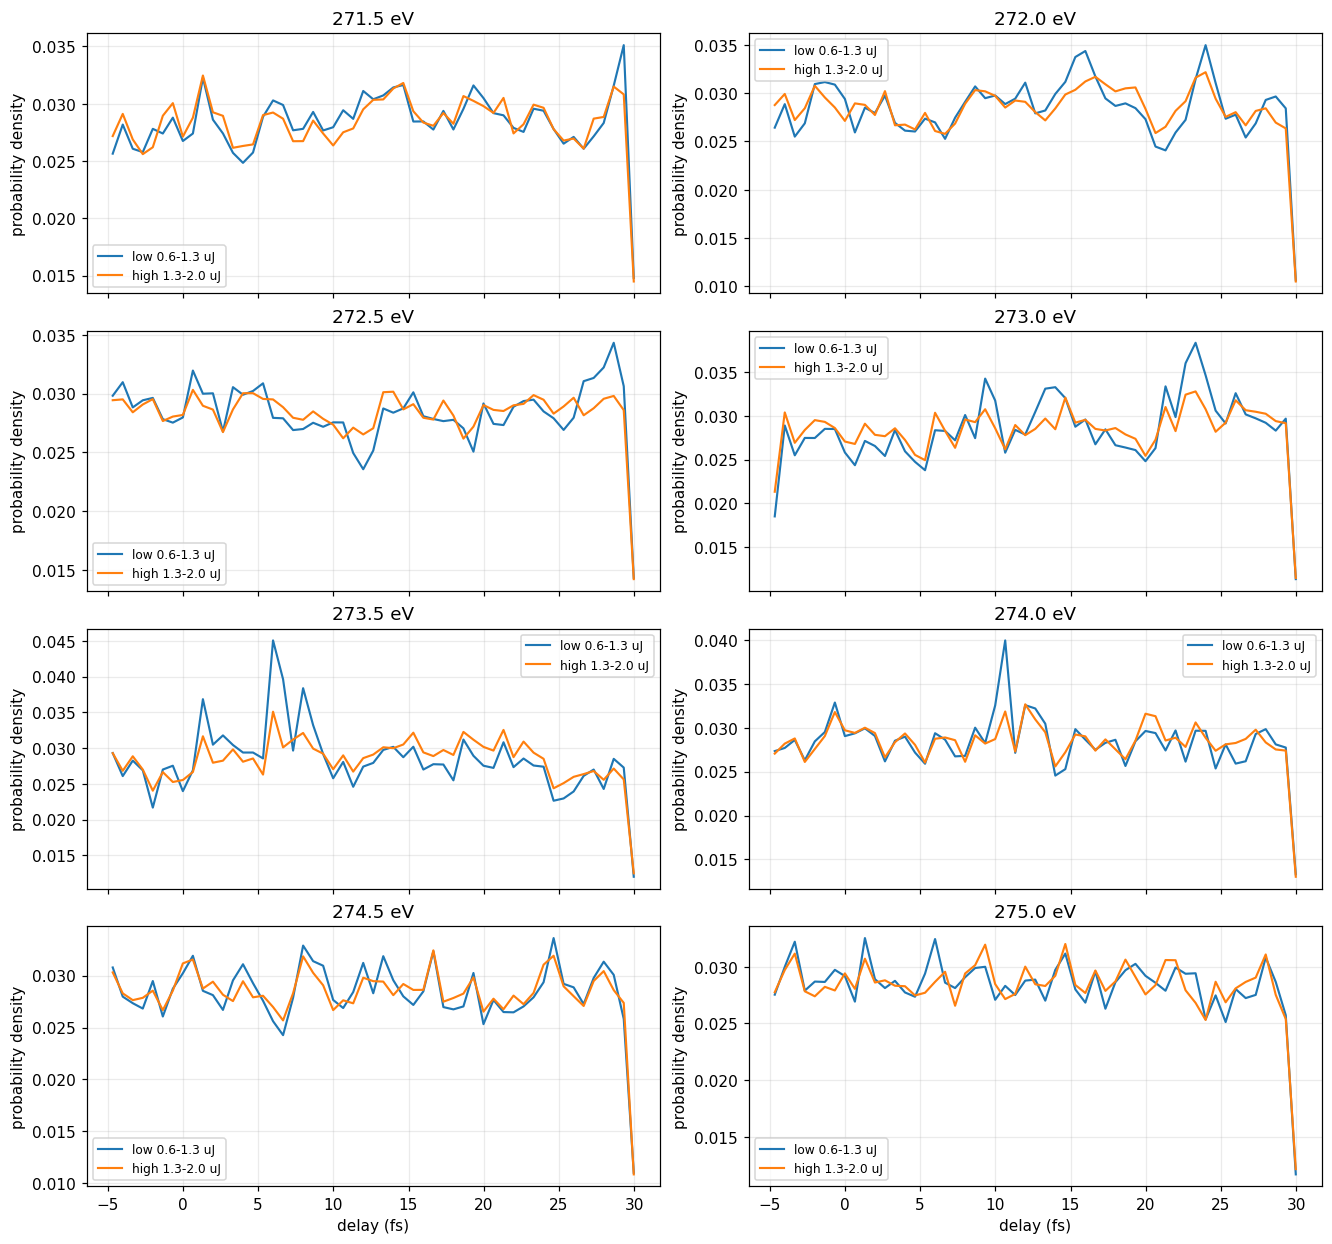

In [159]:
# --- P(delay | low GMD) versus P(delay | high GMD) ---

n_rows = len(delay_diagnostics)
n_cols = 2
n_plot_rows = int(np.ceil(n_rows / n_cols))

fig, axes = plt.subplots(
    n_plot_rows,
    n_cols,
    figsize=(12, 2.8 * n_plot_rows),
    sharex=True,
    constrained_layout=True,
)

axes = np.ravel(axes)

for ax, diag in zip(axes, delay_diagnostics):
    x = diag["delay_centres_fs"]

    ax.plot(
        x,
        diag["p_low"],
        lw=1.4,
        label=f"low {LOW_GMD_RANGE[0]}-{LOW_GMD_RANGE[1]} uJ",
    )
    ax.plot(
        x,
        diag["p_high"],
        lw=1.4,
        label=f"high {HIGH_GMD_RANGE[0]}-{HIGH_GMD_RANGE[1]} uJ",
    )

    ax.set_title(f"{diag['energy']:.1f} eV")
    ax.set_ylabel("probability density")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

for ax in axes[len(delay_diagnostics):]:
    ax.set_visible(False)

for ax in axes[-n_cols:]:
    ax.set_xlabel("delay (fs)")

plt.show()

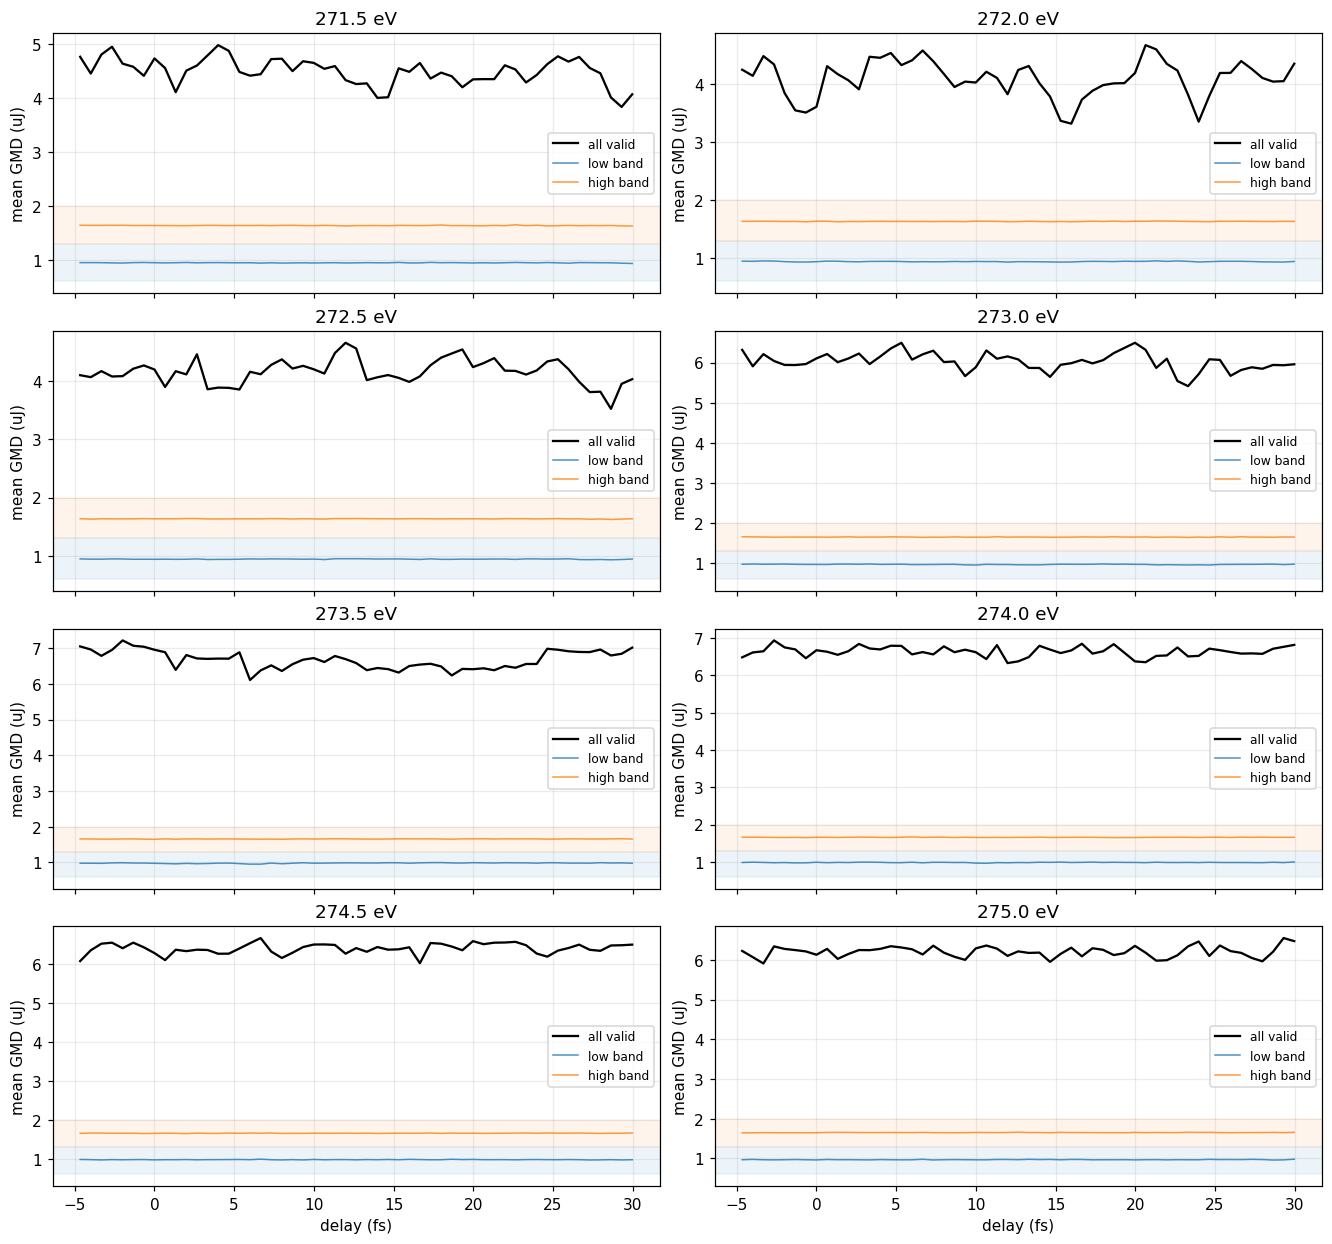

In [160]:
# --- Mean GMD versus delay ---

fig, axes = plt.subplots(
    n_plot_rows,
    n_cols,
    figsize=(12, 2.8 * n_plot_rows),
    sharex=True,
    constrained_layout=True,
)

axes = np.ravel(axes)

for ax, diag in zip(axes, delay_diagnostics):
    x = diag["delay_centres_fs"]

    ax.plot(x, diag["mean_gmd_all"], lw=1.5, color="k", label="all valid")
    ax.plot(x, diag["mean_gmd_low"], lw=1.0, alpha=0.8, label="low band")
    ax.plot(x, diag["mean_gmd_high"], lw=1.0, alpha=0.8, label="high band")

    ax.axhspan(*LOW_GMD_RANGE, color="tab:blue", alpha=0.08)
    ax.axhspan(*HIGH_GMD_RANGE, color="tab:orange", alpha=0.08)

    ax.set_title(f"{diag['energy']:.1f} eV")
    ax.set_ylabel("mean GMD (uJ)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

for ax in axes[len(delay_diagnostics):]:
    ax.set_visible(False)

for ax in axes[-n_cols:]:
    ax.set_xlabel("delay (fs)")

plt.show()

####  Checking delay dependence

In [166]:
# --- Delay-resolved nonlinear slope b(delay, hnu) in one KE window ---

DELAY_SLOPE_KE_RANGE = (190, 220)
DELAY_SLOPE_GMD_EDGES = np.array([0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0])

DELAY_BIN_WIDTH_FS = 5.0
DELAY_SLOPE_MIN_SHOTS = 100

DELAY_CONTRAST_CENTER_ENERGY = 274.0
DELAY_CONTRAST_NEIGHBOUR_ENERGIES = (273.5, 274.5)

DELAY_ZERO_STAGE = 0.0
FS_PER_STAGE_UNIT = 3.33 / 10000.0


def z_to_delay_fs(z):
    return (np.asarray(z, dtype=float) - DELAY_ZERO_STAGE) * FS_PER_STAGE_UNIT


def make_common_delay_edges_fs(rows, bin_width_fs=5.0):
    lo = -np.inf
    hi = np.inf

    for row in rows:
        z_edges = np.asarray(row["z_edges"], dtype=float)
        delay_edges = z_to_delay_fs(z_edges)

        lo = max(lo, float(np.nanmin(delay_edges)))
        hi = min(hi, float(np.nanmax(delay_edges)))

    lo = np.ceil(lo / bin_width_fs) * bin_width_fs
    hi = np.floor(hi / bin_width_fs) * bin_width_fs

    if hi <= lo:
        raise ValueError(f"No common delay overlap after binning: {lo} to {hi} fs")

    return np.arange(lo, hi + 0.5 * bin_width_fs, bin_width_fs)


def weighted_line_fit_y_over_g(x, y, sigma, good):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    good = (
        good
        & np.isfinite(x)
        & np.isfinite(y)
        & np.isfinite(sigma)
        & (sigma > 0)
    )

    if np.count_nonzero(good) < 3:
        return np.nan, np.nan, np.nan, np.nan, int(np.count_nonzero(good))

    xg = x[good]
    yg = y[good]
    wg = 1.0 / sigma[good] ** 2

    S = np.sum(wg)
    Sx = np.sum(wg * xg)
    Sy = np.sum(wg * yg)
    Sxx = np.sum(wg * xg * xg)
    Sxy = np.sum(wg * xg * yg)

    det = S * Sxx - Sx * Sx
    if det <= 0:
        return np.nan, np.nan, np.nan, np.nan, int(np.count_nonzero(good))

    a = (Sxx * Sy - Sx * Sxy) / det
    b = (S * Sxy - Sx * Sy) / det

    sigma_a = np.sqrt(Sxx / det)
    sigma_b = np.sqrt(S / det)

    return a, b, sigma_a, sigma_b, int(np.count_nonzero(good))

In [167]:
# --- Compute b(delay) for each photon energy ---

def delay_resolved_slope_for_row(
    row,
    delay_edges_fs,
    gmd_edges,
    ke_range,
    *,
    chunk_trains=1000,
):
    source_h5 = Path(row["source_h5"])

    delay_edges_fs = np.asarray(delay_edges_fs, dtype=float)
    gmd_edges = np.asarray(gmd_edges, dtype=float)
    z_edges = np.asarray(row["z_edges"], dtype=float)

    n_delay = len(delay_edges_fs) - 1
    n_gmd = len(gmd_edges) - 1

    weights = ke_window_weights_for_tof_bins(tof_edges_ref, ke_range)

    shots = np.zeros((n_delay, n_gmd), dtype=np.int64)
    sum_gmd = np.zeros((n_delay, n_gmd), dtype=float)
    counts = np.zeros((n_delay, n_gmd), dtype=float)
    variance = np.zeros((n_delay, n_gmd), dtype=float)

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=row["trim_start"],
            trim_end=row["trim_end"],
        )

        n_trains = handle["gmd"].shape[0]

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = handle["gmd"][start:stop][row_keep]
            z = handle["z"][start:stop][row_keep]
            tofs = handle["tofs_e"][start:stop][row_keep]

            # First require the shot to belong to one aggregate delay bin.
            aggregate_delay_bin = np.searchsorted(z_edges, z, side="right") - 1
            valid_aggregate_delay = (
                np.isfinite(z)
                & (aggregate_delay_bin >= 0)
                & (aggregate_delay_bin < len(z_edges) - 1)
            )

            delay_fs = z_to_delay_fs(z)
            delay_bin = np.searchsorted(delay_edges_fs, delay_fs, side="right") - 1

            valid = (
                np.isfinite(gmd)
                & valid_aggregate_delay
                & np.isfinite(delay_fs)
                & (delay_bin >= 0)
                & (delay_bin < n_delay)
            )

            gmd_flat = gmd.reshape(-1)
            delay_bin_flat = delay_bin.reshape(-1)
            valid_flat = valid.reshape(-1)
            tofs_flat = tofs.reshape(-1, tofs.shape[-1])

            gmd_bin_flat = np.searchsorted(gmd_edges, gmd_flat, side="right") - 1

            for idelay in range(n_delay):
                in_delay = valid_flat & (delay_bin_flat == idelay)

                if not in_delay.any():
                    continue

                for igmd in range(n_gmd):
                    selected = in_delay & (gmd_bin_flat == igmd)

                    if not selected.any():
                        continue

                    selected_gmd = gmd_flat[selected]

                    hits = tofs_flat[selected].reshape(-1)
                    hits = hits[np.isfinite(hits) & (hits > 0)]

                    hist, _ = np.histogram(hits, bins=tof_edges_ref)

                    shots[idelay, igmd] += int(np.count_nonzero(selected))
                    sum_gmd[idelay, igmd] += float(np.nansum(selected_gmd))
                    counts[idelay, igmd] += float(np.nansum(weights * hist))
                    variance[idelay, igmd] += float(np.nansum((weights ** 2) * hist))

    with np.errstate(invalid="ignore", divide="ignore"):
        mean_gmd = sum_gmd / shots
        y_over_gmd = counts / sum_gmd
        sigma_y_over_gmd = np.sqrt(variance) / sum_gmd

    a = np.full(n_delay, np.nan)
    b = np.full(n_delay, np.nan)
    sigma_a = np.full(n_delay, np.nan)
    sigma_b = np.full(n_delay, np.nan)
    n_fit = np.zeros(n_delay, dtype=int)

    for idelay in range(n_delay):
        good = (
            np.isfinite(mean_gmd[idelay])
            & np.isfinite(y_over_gmd[idelay])
            & np.isfinite(sigma_y_over_gmd[idelay])
            & (sigma_y_over_gmd[idelay] > 0)
            & (shots[idelay] >= DELAY_SLOPE_MIN_SHOTS)
            & (sum_gmd[idelay] > 0)
        )

        ai, bi, sai, sbi, ni = weighted_line_fit_y_over_g(
            mean_gmd[idelay],
            y_over_gmd[idelay],
            sigma_y_over_gmd[idelay],
            good,
        )

        a[idelay] = ai
        b[idelay] = bi
        sigma_a[idelay] = sai
        sigma_b[idelay] = sbi
        n_fit[idelay] = ni

    return {
        "energy": float(row["energy"]),
        "delay_edges_fs": delay_edges_fs,
        "delay_centres_fs": 0.5 * (delay_edges_fs[:-1] + delay_edges_fs[1:]),
        "gmd_edges": gmd_edges,
        "shots": shots,
        "mean_gmd": mean_gmd,
        "a": a,
        "b": b,
        "sigma_a": sigma_a,
        "sigma_b": sigma_b,
        "n_fit": n_fit,
    }


delay_slope_rows_to_use = [
    row for row in full_rows
    if row.get("usable", True)
    and any(np.isclose(row["energy"], e) for e in [DELAY_CONTRAST_CENTER_ENERGY, *DELAY_CONTRAST_NEIGHBOUR_ENERGIES])
]

delay_edges_fs = make_common_delay_edges_fs(
    delay_slope_rows_to_use,
    bin_width_fs=DELAY_BIN_WIDTH_FS,
)

print("Delay edges fs:", delay_edges_fs)

delay_slope_rows = []

for row in delay_slope_rows_to_use:
    print(f"Processing {row['energy']:.1f} eV")
    delay_slope_rows.append(
        delay_resolved_slope_for_row(
            row,
            delay_edges_fs,
            DELAY_SLOPE_GMD_EDGES,
            DELAY_SLOPE_KE_RANGE,
            chunk_trains=CHUNK_TRAINS,
        )
    )

print("Done.")

Delay edges fs: [-5.  0.  5. 10. 15. 20. 25. 30. 35.]
Processing 273.5 eV
Processing 274.0 eV
Processing 274.5 eV
Done.


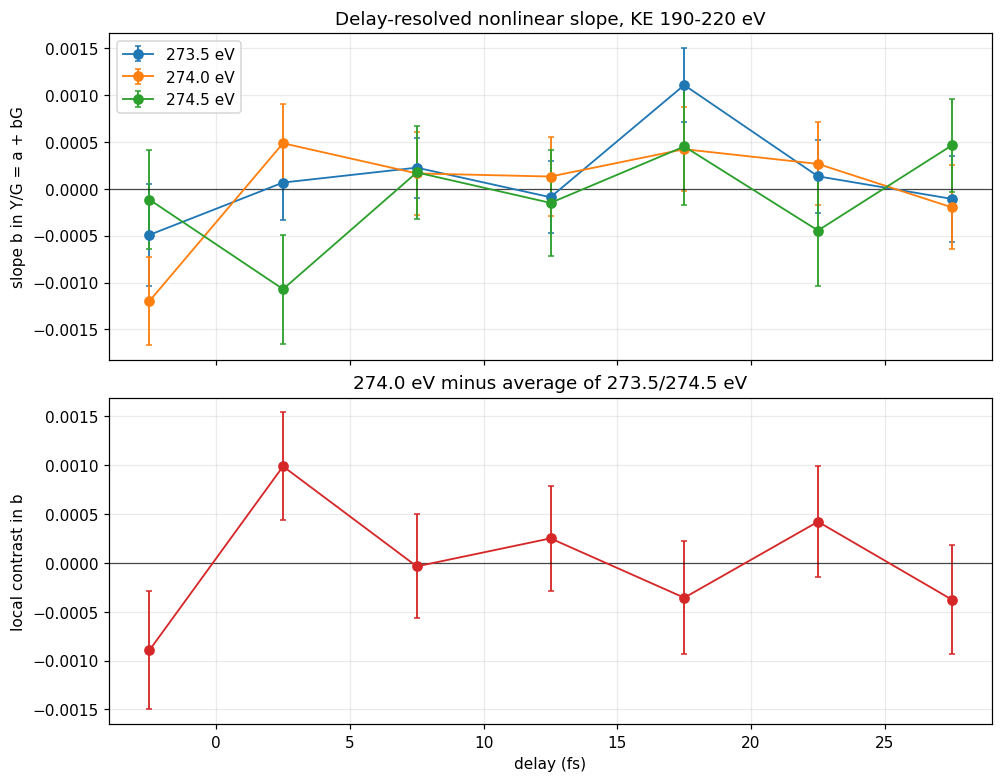

delay_fs   contrast      sigma        z
   -2.50  -0.000895722   0.000603  -1.49
    2.50   0.000988053   0.000551   1.79
    7.50  -3.59552e-05   0.000532  -0.0676
   12.50   0.000250989   0.000541   0.464
   17.50  -0.000356662   0.00058  -0.615
   22.50   0.000421385   0.000567   0.744
   27.50  -0.000374841   0.000562  -0.667
   32.50   nan   nan   nan


In [168]:
# --- Plot b(delay, hnu) and local 274 eV contrast versus delay ---

delay_slope_by_energy = {
    float(row["energy"]): row
    for row in delay_slope_rows
}

missing = [
    e for e in [DELAY_CONTRAST_CENTER_ENERGY, *DELAY_CONTRAST_NEIGHBOUR_ENERGIES]
    if not any(np.isclose(e, have) for have in delay_slope_by_energy)
]
if missing:
    raise ValueError(
        "Missing energies for symmetric delay contrast: "
        + ", ".join(f"{e:.1f}" for e in missing)
        + ". For the 7June dataset, use a one-sided contrast instead."
    )

center = delay_slope_by_energy[DELAY_CONTRAST_CENTER_ENERGY]
left = delay_slope_by_energy[DELAY_CONTRAST_NEIGHBOUR_ENERGIES[0]]
right = delay_slope_by_energy[DELAY_CONTRAST_NEIGHBOUR_ENERGIES[1]]

delay_centres = center["delay_centres_fs"]

contrast_delay = center["b"] - 0.5 * (left["b"] + right["b"])
contrast_delay_sigma = np.sqrt(
    center["sigma_b"] ** 2
    + 0.25 * left["sigma_b"] ** 2
    + 0.25 * right["sigma_b"] ** 2
)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 7),
    sharex=True,
    constrained_layout=True,
)

for row in [left, center, right]:
    axes[0].errorbar(
        row["delay_centres_fs"],
        row["b"],
        yerr=row["sigma_b"],
        fmt="o-",
        capsize=2,
        lw=1.2,
        label=f"{row['energy']:.1f} eV",
    )

axes[0].axhline(0.0, color="k", lw=0.8, alpha=0.7)
axes[0].set_ylabel("slope b in Y/G = a + bG")
axes[0].set_title(
    f"Delay-resolved nonlinear slope, KE {DELAY_SLOPE_KE_RANGE[0]}-"
    f"{DELAY_SLOPE_KE_RANGE[1]} eV"
)
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].errorbar(
    delay_centres,
    contrast_delay,
    yerr=contrast_delay_sigma,
    fmt="o-",
    capsize=2,
    lw=1.2,
    color="tab:red",
)

axes[1].axhline(0.0, color="k", lw=0.8, alpha=0.7)
axes[1].set_xlabel("delay (fs)")
axes[1].set_ylabel("local contrast in b")
axes[1].set_title(
    f"{center['energy']:.1f} eV minus average of "
    f"{left['energy']:.1f}/{right['energy']:.1f} eV"
)
axes[1].grid(alpha=0.25)

plt.show()

with np.errstate(invalid="ignore", divide="ignore"):
    contrast_delay_z = contrast_delay / contrast_delay_sigma

print("delay_fs   contrast      sigma        z")
for d, c, s, zval in zip(delay_centres, contrast_delay, contrast_delay_sigma, contrast_delay_z):
    print(f"{d:8.2f}  {c: .6g}  {s: .3g}  {zval: .3g}")

#### Several GMD ranges to test SDU affecting energy

In [172]:
# --- Sensitivity of collapsed local 274 eV contrast to GMD range ---

GMD_RANGE_TESTS = {
    "0.6-2.0 uJ": np.array([0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]),
    "1.0-3.0 uJ": np.array([1.0, 1.3, 1.6, 1.9, 2.2, 2.6, 3.0]),
    "1.5-4.0 uJ": np.array([1.5, 1.9, 2.3, 2.7, 3.1, 3.5, 4.0]),
}

GMD_RANGE_TEST_KE_RANGE = (190, 220)
GMD_RANGE_TEST_ENERGY_RANGE = (274.0, 276.0)

# Symmetric if available; otherwise use one-sided higher-energy background.
# --- Explicit local-contrast configuration ---

# Use this if 273.5, 274.0, 274.5 are available.
USE_SYMMETRIC_274_CONTRAST = any(np.isclose([row["energy"] for row in full_rows], 273.5))

if USE_SYMMETRIC_274_CONTRAST:
    GMD_RANGE_TEST_ENERGY_RANGE = (273.5, 276.0)
    GMD_RANGE_TEST_CENTER_ENERGY = 274.0
    GMD_RANGE_TEST_BACKGROUND_ENERGIES = (273.5, 274.5)
else:
    GMD_RANGE_TEST_ENERGY_RANGE = (274.0, 276.0)
    GMD_RANGE_TEST_CENTER_ENERGY = 274.0
    GMD_RANGE_TEST_BACKGROUND_ENERGIES = (274.5, 275.0)

print("Contrast mode:", "symmetric" if USE_SYMMETRIC_274_CONTRAST else "one-sided")
print("Energy range:", GMD_RANGE_TEST_ENERGY_RANGE)
print("Center:", GMD_RANGE_TEST_CENTER_ENERGY)
print("Background:", GMD_RANGE_TEST_BACKGROUND_ENERGIES)

Contrast mode: symmetric
Energy range: (273.5, 276.0)
Center: 274.0
Background: (273.5, 274.5)


In [170]:
# --- Build b(hnu) for each tested GMD range ---

def fit_integrated_slope_for_rows(rows, gmd_edges, ke_range):
    out_rows = []
    out_fits = []

    for row in rows:
        energy = float(row["energy"])
        if not row.get("usable", True):
            continue
        if not (GMD_RANGE_TEST_ENERGY_RANGE[0] <= energy <= GMD_RANGE_TEST_ENERGY_RANGE[1]):
            continue

        diag = gmd_binned_ke_yield_for_row(
            row,
            gmd_edges,
            ke_range,
            tof_edges=tof_edges_ref,
            chunk_trains=CHUNK_TRAINS,
        )
        fit = fit_yield_over_gmd_slope(diag)

        out_rows.append(diag)
        out_fits.append(fit)

    return out_rows, out_fits


range_test_results = {}

for label, edges in GMD_RANGE_TESTS.items():
    print("Processing", label)

    rows_i, fits_i = fit_integrated_slope_for_rows(
        full_rows,
        edges,
        GMD_RANGE_TEST_KE_RANGE,
    )

    range_test_results[label] = {
        "edges": edges,
        "rows": rows_i,
        "fits": fits_i,
    }

print("Done.")

Processing 0.6-2.0 uJ
Processing 1.0-3.0 uJ
Processing 1.5-4.0 uJ
Done.


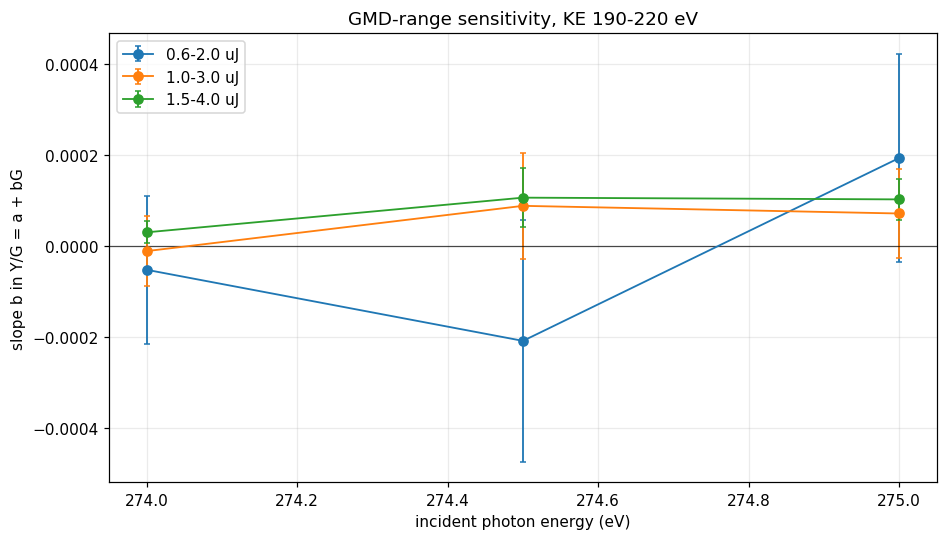

In [171]:
# --- Plot b(hnu) for each GMD range ---

fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)

for label, result in range_test_results.items():
    fits = result["fits"]

    energy = np.array([fit["energy"] for fit in fits], dtype=float)
    b = np.array([fit["b"] for fit in fits], dtype=float)
    sigma_b = np.array([fit["sigma_b"] for fit in fits], dtype=float)

    good = np.isfinite(energy) & np.isfinite(b) & np.isfinite(sigma_b) & (sigma_b > 0)

    ax.errorbar(
        energy[good],
        b[good],
        yerr=sigma_b[good],
        fmt="o-",
        capsize=2,
        lw=1.2,
        label=label,
    )

ax.axhline(0.0, color="k", lw=0.8, alpha=0.7)
ax.set_xlabel("incident photon energy (eV)")
ax.set_ylabel("slope b in Y/G = a + bG")
ax.set_title(
    f"GMD-range sensitivity, KE {GMD_RANGE_TEST_KE_RANGE[0]}-"
    f"{GMD_RANGE_TEST_KE_RANGE[1]} eV"
)
ax.grid(alpha=0.25)
ax.legend()

plt.show()

#### Do we have enough sensitivity

energy     low        high       delta      sigma_d    mean       R        sigma_R
 271.50   0.0061366   0.0062804   0.00014377   0.00022   0.0062085   0.023157   0.0354
 272.00   0.0059208   0.0062093   0.00028848   0.000161   0.006065   0.047564   0.0266
 272.50   0.0030591   0.0033099   0.00025084   0.000117   0.0031845   0.078769   0.0367
 273.00   0.001306   0.0013679   6.1915e-05   0.000107   0.001337   0.04631   0.0801
 273.50   0.0011916   0.0011623  -2.9282e-05   0.000129   0.0011769  -0.024881   0.11
 274.00   0.0013002   0.0013837   8.3447e-05   0.000135   0.0013419   0.062184   0.101
 274.50   0.0023992   0.002124  -0.0002752   0.000168   0.0022616  -0.12169   0.0743
 275.00   0.0029162   0.0029383   2.2108e-05   0.000174   0.0029272   0.0075526   0.0595


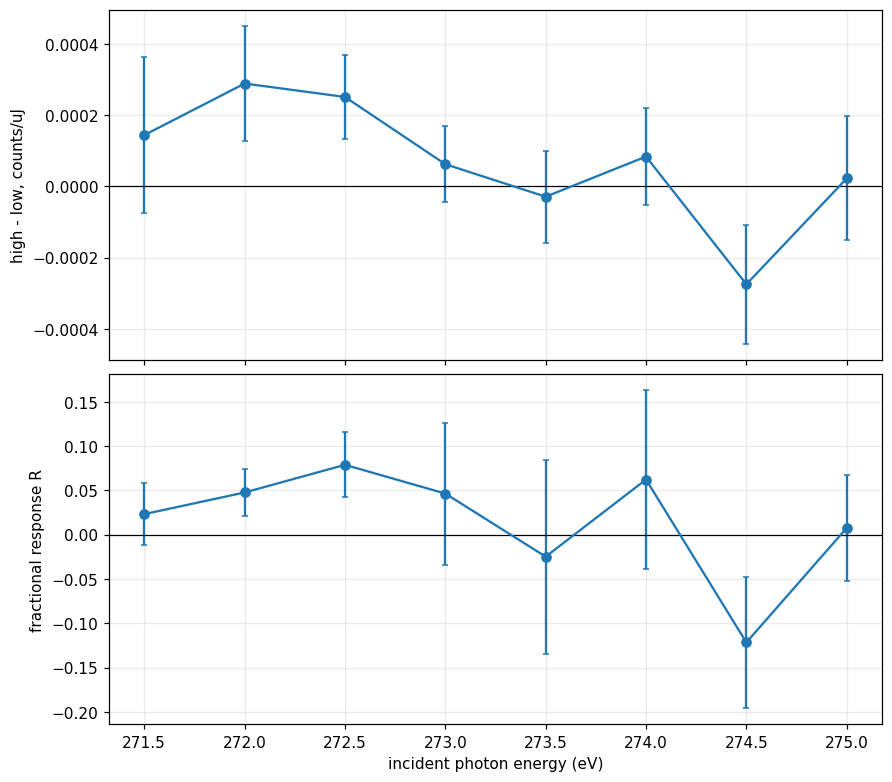

In [173]:
# --- Fractional two-bin response in selected KE window ---

FRACTIONAL_RESPONSE_KE_RANGE = (190, 220)


def two_bin_fractional_response_for_row(row, ke_range):
    low, sigma_low, _ = integrate_group_with_uncertainty(
        row["low"],
        tof_edges_ref,
        ke_range,
    )
    high, sigma_high, _ = integrate_group_with_uncertainty(
        row["high"],
        tof_edges_ref,
        ke_range,
    )

    delta = high - low
    mean_signal = 0.5 * (high + low)

    sigma_delta = np.sqrt(sigma_high ** 2 + sigma_low ** 2)
    sigma_mean = 0.5 * np.sqrt(sigma_high ** 2 + sigma_low ** 2)

    with np.errstate(invalid="ignore", divide="ignore"):
        R = delta / mean_signal
        sigma_R = abs(R) * np.sqrt(
            (sigma_delta / delta) ** 2
            + (sigma_mean / mean_signal) ** 2
        )

    if not np.isfinite(sigma_R):
        sigma_R = np.nan

    return {
        "energy": float(row["energy"]),
        "low": low,
        "high": high,
        "sigma_low": sigma_low,
        "sigma_high": sigma_high,
        "delta": delta,
        "sigma_delta": sigma_delta,
        "mean_signal": mean_signal,
        "sigma_mean": sigma_mean,
        "R": R,
        "sigma_R": sigma_R,
    }


fractional_response_rows = [
    two_bin_fractional_response_for_row(row, FRACTIONAL_RESPONSE_KE_RANGE)
    for row in full_rows
    if row.get("usable", True)
]

print("energy     low        high       delta      sigma_d    mean       R        sigma_R")
for r in fractional_response_rows:
    print(
        f"{r['energy']:7.2f}  "
        f"{r['low']: .5g}  {r['high']: .5g}  "
        f"{r['delta']: .5g}  {r['sigma_delta']: .3g}  "
        f"{r['mean_signal']: .5g}  "
        f"{r['R']: .5g}  {r['sigma_R']: .3g}"
    )

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, constrained_layout=True)

energies = np.array([r["energy"] for r in fractional_response_rows])
delta = np.array([r["delta"] for r in fractional_response_rows])
sigma_delta = np.array([r["sigma_delta"] for r in fractional_response_rows])
R = np.array([r["R"] for r in fractional_response_rows])
sigma_R = np.array([r["sigma_R"] for r in fractional_response_rows])

axes[0].errorbar(energies, delta, yerr=sigma_delta, fmt="o-", capsize=2)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_ylabel("high - low, counts/uJ")
axes[0].grid(alpha=0.25)

axes[1].errorbar(energies, R, yerr=sigma_R, fmt="o-", capsize=2)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("incident photon energy (eV)")
axes[1].set_ylabel("fractional response R")
axes[1].grid(alpha=0.25)

plt.show()

In [176]:
# --- Expected cold absolute signal if static fractional response were present ---

STATIC_R_274 = 0.19088           # paste static R at 274 eV here
STATIC_SIGMA_R_274 =  0.0469 # paste static sigma_R if wanted

target_energy = 274.0
idx = int(np.nanargmin(np.abs(energies - target_energy)))
cold = fractional_response_rows[idx]

expected_delta_cold = STATIC_R_274 * cold["mean_signal"]

if np.isfinite(STATIC_SIGMA_R_274):
    expected_sigma_from_static_R = abs(cold["mean_signal"]) * STATIC_SIGMA_R_274
else:
    expected_sigma_from_static_R = np.nan

expected_z_in_cold = expected_delta_cold / cold["sigma_delta"]

print(f"Cold energy used: {cold['energy']:.3f} eV")
print(f"Cold mean signal: {cold['mean_signal']:.6g} counts/uJ")
print(f"Cold observed delta: {cold['delta']:.6g} +/- {cold['sigma_delta']:.3g}")
print(f"Static fractional R: {STATIC_R_274:.6g}")
print(f"Expected cold delta from static R: {expected_delta_cold:.6g}")
print(f"Expected cold detection significance: {expected_z_in_cold:.3g} sigma")
print(f"Uncertainty from static R only: {expected_sigma_from_static_R:.3g}")

Cold energy used: 274.000 eV
Cold mean signal: 0.00134193 counts/uJ
Cold observed delta: 8.34469e-05 +/- 0.000135
Static fractional R: 0.19088
Expected cold delta from static R: 0.000256147
Expected cold detection significance: 1.9 sigma
Uncertainty from static R only: 6.29e-05


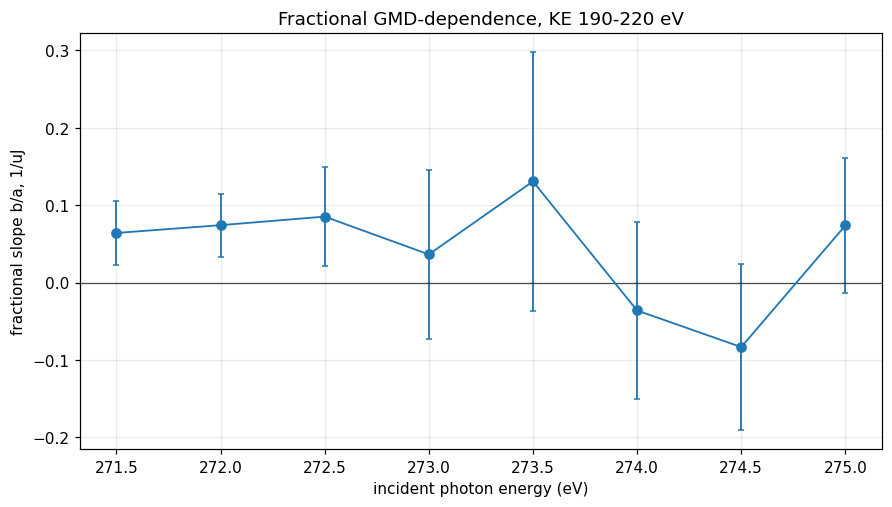

energy      a            b            b/a          sigma_b/a
 271.50   0.00570504   0.000365454   0.0640582   0.0408
 272.00   0.00552   0.000409144   0.0741204   0.0408
 272.50   0.00286618   0.000244138   0.0851787   0.0636
 273.00   0.00127117   4.61954e-05   0.0363408   0.11
 273.50   0.000965381   0.000126148   0.130671   0.167
 274.00   0.00142756  -5.15628e-05  -0.0361196   0.114
 274.50   0.00249185  -0.000207743  -0.083369   0.108
 275.00   0.00263201   0.000194193   0.0737812   0.0876


In [175]:
# --- Fractional nonlinear slope b/a from multi-bin fits ---

fit_energy = np.array([fit["energy"] for fit in gmd_response_fits], dtype=float)
fit_a = np.array([fit["a"] for fit in gmd_response_fits], dtype=float)
fit_b = np.array([fit["b"] for fit in gmd_response_fits], dtype=float)
fit_sigma_a = np.array([fit["sigma_a"] for fit in gmd_response_fits], dtype=float)
fit_sigma_b = np.array([fit["sigma_b"] for fit in gmd_response_fits], dtype=float)

with np.errstate(invalid="ignore", divide="ignore"):
    frac_slope = fit_b / fit_a

    # Approximate uncertainty, ignoring covariance between a and b.
    sigma_frac_slope = np.sqrt(
        (fit_sigma_b / fit_a) ** 2
        + ((fit_b * fit_sigma_a) / (fit_a ** 2)) ** 2
    )

good = (
    np.isfinite(fit_energy)
    & np.isfinite(frac_slope)
    & np.isfinite(sigma_frac_slope)
    & (sigma_frac_slope > 0)
)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)

ax.errorbar(
    fit_energy[good],
    frac_slope[good],
    yerr=sigma_frac_slope[good],
    fmt="o-",
    capsize=2,
    lw=1.2,
)

ax.axhline(0.0, color="k", lw=0.8, alpha=0.7)
ax.set_xlabel("incident photon energy (eV)")
ax.set_ylabel("fractional slope b/a, 1/uJ")
ax.set_title(
    f"Fractional GMD-dependence, KE {GMD_RESPONSE_KE_RANGE[0]}-"
    f"{GMD_RESPONSE_KE_RANGE[1]} eV"
)
ax.grid(alpha=0.25)

plt.show()

print("energy      a            b            b/a          sigma_b/a")
for e, a, b, r, sr in zip(fit_energy, fit_a, fit_b, frac_slope, sigma_frac_slope):
    print(f"{e:7.2f}  {a: .6g}  {b: .6g}  {r: .6g}  {sr: .3g}")